# MCS track statistics of all sources in one format

Loads the **combined track-statistics Parquet files** of the observation, the SCREAM simulations and the E3SM simulations, checks that
they have the same columns, summarizes them, and then runs the track-statistics analyses of `plot_tropical_mcs_trackstats_land_ocean.ipynb`
for all sources, with every source and every setting configured in one place: the land / ocean classification and the lifetime statistics, the
**box-whisker plots**, the **table of % differences with significance tests**, and the **composite life cycles** (by lifetime, land versus
ocean, interpolated and raw time). Run it on a compute node (about 20 GB of memory per copy of the table).

### The unified format

Every source has one file `mcs_tracks_final_combined_{region}_{first_year}_{last_year}.parquet` with **one row per track and time step**
and the same 69 columns (`local_track`, `relative_step`, the per-track, per-time and largest-precipitation-feature (`pf_*`) variables,
`relative_time_h`, `track_duration_h`, `period`). It is written by `scripts/combine_filter_mcs_trackstats.py` from

* the dense netCDF files `mcs_tracks_final_*.nc` of the old pipeline (OBS, SCREAM), or
* the row-table folders `mcs_tracks_final_*.rows` of the new pipeline (`stats_format: rows`: `tracks`, `entries`, `fragments`, `meta.json`;
  E3SM), joined into the same table: the per-track variables of `tracks` are repeated on every row, the per-time variables are the
  `entries`, `pf_*__0` is the largest precipitation feature, and the merge / split areas are the sums over `fragments`.

The two routes give identical tables (unit test and check on real files). `period` is the calendar year in which the track starts.

**A variable that a source does not have** (its PyFLEXTRKR version did not write it: the SCREAM Cess2 file of January 2026 has no
`total_volrain` and `total_heavyvolrain`) is NaN in the combined file, and the script prints a warning. The check below lists such
columns for every source. A sum over an all-NaN column gives 0 (pandas), so leave such a source out of analyses of those variables.

**How to use:** change only the *Configuration* cell. The sources are labeled by their grid spacing (`3-km CTL`, `13-km TUNE`, `25-km`, ...).

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display

# Fonts: the same in all notebooks of this SCREAM / E3SM evaluation
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['mathtext.fontset'] = 'stix'

## Configuration
All user-editable items: the output folder, the region, and for every source its label, the folder and years of its combined file, and
the color and line style used in all plots. The order of `SOURCES` is the plotting order.

In [2]:
# ====================================================================================================================================
# CONFIGURATION (the only cell to edit)
# ====================================================================================================================================

# ---- Output ----------------------------------------------------------------------------------------------------------------------
figdir = '/pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/'   # folder of the saved figures (created if missing)
dpi = 200

# ---- Region of the combined files (the file name has it): 'tropics' or 'global' ----------------------------------------------------
REGION = 'tropics'

# ---- Sources, in plotting order ----------------------------------------------------------------------------------------------------
# label                  text in tables, titles and legends
# combined_dir           folder of the combined Parquet file
# start_year, end_year   years in the file name: mcs_tracks_final_combined_{REGION}_{start_year}_{end_year}.parquet
# color, linewidth, linestyle   style of the source in every plot
CFS = '/global/cfs/cdirs/m1867/zfeng/SCREAM-decadal'
E3SM = '/global/cfs/cdirs/m1867/zfeng/E3SM_polun'                 # CFS copy (identical to the pscratch tree, checked 2026-11-18)
SOURCES = {
    'obs': dict(label='OBS', combined_dir=f'{CFS}/mcs_global_v3/MCSMIP/stats', start_year=2007, end_year=2017,
                color='black', linewidth=3.0, linestyle='-'),
    'scream3_ctl': dict(label='3-km CTL', combined_dir=f'{CFS}/ne1024/stats', start_year=1995, end_year=2005,
                        color='dodgerblue', linewidth=1.8, linestyle='-'),
    'scream3_tune': dict(label='3-km TUNE', combined_dir='/global/cfs/cdirs/m1867/zfeng/E3SM/SCREAMv1/cess2/global/mcs/stats',
                         start_year=2019, end_year=2021, color='navy', linewidth=1.8, linestyle='-'),
    'scream13_ctl': dict(label='13-km CTL', combined_dir=f'{CFS}/ne256/ctl/stats', start_year=1995, end_year=2005,
                         color='tomato', linewidth=1.8, linestyle='-'),
    'scream13_tune': dict(label='13-km TUNE', combined_dir=f'{CFS}/ne256/tune/stats', start_year=1995, end_year=2005,
                          color='forestgreen', linewidth=1.8, linestyle='-'),
    'e3sm25': dict(label='25-km', combined_dir=f'{E3SM}/ne120_remap_0.1deg/mcs_tbpf_hr2p0/stats', start_year=2009, end_year=2011,
                   color='darkviolet', linewidth=1.8, linestyle='-'),
    'e3sm100': dict(label='100-km', combined_dir=f'{E3SM}/ne30_remap_0.1deg/mcs_tbpf_hr2p0/stats', start_year=2009, end_year=2020,
                    color='saddlebrown', linewidth=1.8, linestyle='-'),
}

# Derived from SOURCES (do not edit): the labels in plotting order and the color of every label
SOURCE_ORDER = [cfg['label'] for cfg in SOURCES.values()]
SOURCE_COLORS = {cfg['label']: cfg['color'] for cfg in SOURCES.values()}

# ---- The reference of the significance table ----------------------------------------------------------------------------------------
REF_SOURCE = 'obs'                # key of SOURCES: the table gives the % difference of every other source relative to this one

# ---- Land / ocean classification (lifetime minimum / maximum of pf_landfrac of a track) -----------------------------------------------
LAND_MINFRAC = 0.9                # land track: the lifetime-minimum pf_landfrac is above this
OCEAN_MAXFRAC = 0.1               # ocean track: the lifetime-maximum pf_landfrac is below this
SURFACE_ORDER = ['Land', 'Ocean'] # order of the surfaces in the plots

# ---- Lifetime statistics: one row per track, a column {variable}_lt_{max|min|mean|median|sum} for every variable listed -------------------
max_vars = ['ccs_area_all',       # cloud-shield area including merged and split systems (km2)
            'ccs_area',           # cold cloud shield area (km2)
            'core_area',          # cold core area (km2)
            'pf_area',            # precipitation feature area (km2)
            'pf_majoraxis',       # PF major axis length (km)
            'pf_maxrainrate',     # PF maximum rain rate (mm/h)
            'pf_rainrate',        # PF mean rain rate (mm/h)
            'rainrate_p95']       # PF rain rate 95th percentile (mm/h)
min_vars = ['corecold_mintb',     # minimum cold core brightness temperature (K)
            'core_meantb']        # mean convective core brightness temperature (K)
median_vars = ['movement_speed']  # movement speed (m/s)
mean_vars = ['heavy_rain_ratio',  # heavy rain share of the rain volume
             'movement_speed']
sum_vars = ['total_volrain',      # rain volume (mm/h km2)
            'total_heavyvolrain', # heavy rain volume (mm/h km2)
            'total_rain',         # total precipitation (mm/h)
            'total_heavyrain']    # total heavy precipitation (mm/h)

# ---- Box-whisker plots: the variable, title and scale of every panel (rows x columns) -------------------------------------------------
lt_variables = [['track_duration_h', 'ccs_area_all_lt_max', 'corecold_mintb_lt_min'],
                ['pf_majoraxis_lt_max', 'pf_rainrate_lt_max', 'rainrate_p95_lt_max'],
                ['movement_speed_lt_median', 'total_volrain_lt_sum', 'heavy_rain_ratio_lt_mean']]
lt_panel_titles = [['(a) Lifetime', '(b) Max CCS Area', '(c) Min Tb'],
                   ['(d) Max PF Major Axis', '(e) Max PF Mean Rain Rate', '(f) Max P95 Rain Rate'],
                   ['(g) Median Movement Speed', '(h) Total Volumetric Rain', '(i) Mean Heavy Rain Ratio']]
lt_yscale = [['linear', 'log', 'linear'], ['linear', 'linear', 'linear'], ['linear', 'log', 'linear']]
lt_labels = {'track_duration_h': 'Track Duration (h)', 'ccs_area_all_lt_max': 'CCS Area (km²)', 'ccs_area_lt_max': 'CCS Area (km²)',
             'pf_area_lt_max': 'PF Area (km²)', 'pf_majoraxis_lt_max': 'Major Axis Length (km)', 'pf_rainrate_lt_max': 'Mean Rain Rate (mm/h)',
             'rainrate_p95_lt_max': 'P95 Rain Rate (mm/h)', 'movement_speed_lt_median': 'Movement Speed (m/s)',
             'corecold_mintb_lt_min': 'Min Tb (K)', 'total_volrain_lt_sum': 'Rain Volume (mm km²)', 'heavy_rain_ratio_lt_mean': 'Heavy Rain Ratio'}
box_whis = (5, 95)                # percentiles of the whiskers
box_notch = True                  # notched boxes (the notch is the 95 % confidence interval of the median)
box_width = 0.7                   # total width of the boxes of one surface (the boxes of all sources share it)
box_figsize = (15, 12)            # [inch]

# ---- Significance table: the rows (HTML allowed in the labels), the test and the groups -------------------------------------------------
STAT_VARS = {'track_duration_h': 'Lifetime<br>(h)', 'ccs_area_all_lt_max': 'Max CCS Area<br>(km<sup>2</sup>)',
             'corecold_mintb_lt_min': 'Min Tb<br>(K)', 'pf_majoraxis_lt_max': 'Max PF Major Axis<br>(km)',
             'pf_rainrate_lt_max': 'Max Mean Rain Rate<br>(mm h<sup>-1</sup>)', 'rainrate_p95_lt_max': 'Max P95 Rain Rate<br>(mm h<sup>-1</sup>)',
             'movement_speed_lt_median': 'Median Move. Speed<br>(m s<sup>-1</sup>)', 'total_volrain_lt_sum': 'Total Rain Volume<br>(mm km<sup>2</sup>)',
             'heavy_rain_ratio_lt_mean': 'Heavy Rain Ratio'}
SURFACES = [('Land', 'L'), ('Ocean', 'O')]   # (surface value, short label in the table)
ALPHA = 0.01                      # significance level of the Mann-Whitney U test
NONSIG = '✘'                      # appended to a % difference that is not significant
MIN_N = 5                         # smallest number of tracks of a group in the table

# ---- Composites of the life cycle -------------------------------------------------------------------------------------------------------
COMPOSITE_MODES = ['interpolated', 'raw']     # 'interpolated': every track stretched to the centre of its duration bin; 'raw': relative time in hours
comp_var_specs = {'ccs_area': dict(ylabel='CCS Area (km²)'), 'corecold_mintb': dict(ylabel='Min Tb (K)'),
                  'pf_area': dict(ylabel='PF Area (km²)'), 'pf_majoraxis': dict(ylabel='PF Major Axis Length (km)'),
                  'rainrate_p95': dict(ylabel='P95 Rain Rate (mm/h)'), 'total_volrain': dict(ylabel='Total Rain Volume (mm/h km²)')}
dur_bins = [(4, 10), (10, 14), (14, 18), (18, 22), (22, 26), (26, 30)]    # half-open duration bins [lo, hi) in hours
MIN_TRACKS_COMPOSITE = 20         # a bin with fewer tracks is not composited
overlay_bins = {'10–14 h': dict(ls='--'), '22–26 h': dict(ls='-')}       # bins of the land-vs-ocean figure and their line style (en dash in the label)
overlay_shading_bin = '10–14 h'   # the bin of the figure with the shaded interquartile range
OVERLAY_SHADING_ALPHA = 0.2       # transparency of the shaded interquartile ranges (7 sources overlap)
OVERLAY_LW_OBS = 4                # line width of the reference source in the overlay figures
OVERLAY_LW = 3                    # line width of the other sources
lifecycle_fontsize = 14           # base font size of the life-cycle figures
FIGURE_FORMATS = ['png']          # formats of the saved figures, for example ['png', 'pdf']

## Load the combined files
One DataFrame per source; the columns must be identical (the unified format). The sources are concatenated with a `source` column that
holds the label.

In [3]:
os.makedirs(figdir, exist_ok=True)


def combined_path(cfg, region=REGION):
    """
    Path of the combined Parquet file of one source.

    Args:
        cfg: dict
            One entry of SOURCES (combined_dir, start_year, end_year).
        region: str (default: REGION)
            Region in the file name.

    Returns:
        path: str
    """
    name = f"mcs_tracks_final_combined_{region}_{cfg['start_year']}_{cfg['end_year']}.parquet"
    return os.path.join(cfg['combined_dir'], name)


def load_sources(sources):
    """
    Read the combined file of every source and check that all have the same columns.

    Args:
        sources: dict
            SOURCES (label, combined_dir, start_year, end_year per source).

    Returns:
        frames: dict
            source key -> DataFrame (one row per track and time step; no `source` column yet).

    Raises:
        FileNotFoundError: a combined file does not exist (the message says how to make it).
        ValueError: the columns of a source differ from those of the first source.
    """
    frames = {}
    # Loop over the sources: read, report, and compare the columns with the first source
    for key, cfg in sources.items():
        path = combined_path(cfg)
        if not os.path.exists(path):
            raise FileNotFoundError(
                f"{cfg['label']}: combined Parquet not found:\n  {path}\n  make it with scripts/combine_filter_mcs_trackstats.py "
                f"(--pattern '*mcs_tracks_final_*.nc' for dense files, '*.rows' for row-table folders)")
        df = pd.read_parquet(path)
        frames[key] = df
        print(f"{cfg['label']:>20s}: {len(df):>10,} rows | {df['local_track'].nunique():>7,} tracks | {os.path.basename(path)}")
        if list(df.columns) != list(next(iter(frames.values())).columns):
            raise ValueError(f"{cfg['label']}: the columns differ from those of the first source")
    return frames


frames = load_sources(SOURCES)

# One table of all sources, with the label in `source`
df = pd.concat([f.assign(source=SOURCES[k]['label']) for k, f in frames.items()], ignore_index=True)
print(f'\nAll sources: {df.shape[0]:,} rows x {df.shape[1]} columns (including `source`)')

                 OBS:  6,017,124 rows | 337,321 tracks | mcs_tracks_final_combined_tropics_2007_2017.parquet


            3-km CTL:  7,358,524 rows | 413,609 tracks | mcs_tracks_final_combined_tropics_1995_2005.parquet


           3-km TUNE:    889,852 rows |  54,010 tracks | mcs_tracks_final_combined_tropics_2019_2021.parquet


           13-km CTL:  7,635,846 rows | 425,747 tracks | mcs_tracks_final_combined_tropics_1995_2005.parquet


          13-km TUNE:  7,972,159 rows | 430,223 tracks | mcs_tracks_final_combined_tropics_1995_2005.parquet


               25-km:  1,608,183 rows |  66,786 tracks | mcs_tracks_final_combined_tropics_2009_2011.parquet


              100-km:  1,265,521 rows |  30,998 tracks | mcs_tracks_final_combined_tropics_2009_2020.parquet



All sources: 32,747,209 rows x 70 columns (including `source`)


## Check: the same columns and data types in every source

In [4]:
# Data types of every column and source; the table shows only the columns whose type differs between sources
dtypes = pd.DataFrame({SOURCES[k]['label']: f.dtypes.astype(str) for k, f in frames.items()})
different = dtypes[dtypes.nunique(axis=1) > 1]
print(f'{dtypes.shape[0]} columns in every source; {len(different)} column(s) with different data types')
display(different)

# The per-source frames are no longer needed (the concatenated table `df` has everything): free their memory
del frames

69 columns in every source; 0 column(s) with different data types


,OBS,3-km CTL,3-km TUNE,13-km CTL,13-km TUNE,25-km,100-km


## Check: columns that are entirely missing in a source

In [5]:
# For every source: the columns that are NaN in every row (a variable that the source does not have)
for cfg in SOURCES.values():
    part = df[df['source'] == cfg['label']]
    empty = [c for c in part.columns if part[c].isna().all()]
    print(f"{cfg['label']:>20s}: {empty if empty else 'every column has values'}")

                 OBS: every column has values


            3-km CTL: every column has values


           3-km TUNE: every column has values


           13-km CTL: every column has values


          13-km TUNE: every column has values


               25-km: every column has values


              100-km: every column has values


## Summary: tracks, durations and tracks per year

In [6]:
# One row per track: duration and the year in which the track starts
tracks = df.drop_duplicates(subset=['source', 'local_track'])

summary = (tracks.groupby('source')['track_duration_h']
           .describe(percentiles=[0.25, 0.5, 0.75, 0.95])[['count', 'mean', '25%', '50%', '75%', '95%', 'max']]
           .round(1).reindex(SOURCE_ORDER))
print('Track count and duration (h):')
display(summary)

per_year = tracks.groupby(['period', 'source']).size().unstack(fill_value=0)[SOURCE_ORDER]
print('\nTracks per year (the year in which the track starts):')
display(per_year)

Track count and duration (h):


,count,mean,25%,50%,75%,95%,max
source,,,,,,,
OBS,337321.0,17.8,11.0,15.0,22.0,38.0,289.0
3-km CTL,413609.0,17.8,10.0,14.0,21.0,42.0,583.0
3-km TUNE,54010.0,16.5,10.0,14.0,20.0,35.0,383.0
13-km CTL,425747.0,17.9,11.0,15.0,21.0,38.0,428.0
13-km TUNE,430223.0,18.5,11.0,15.0,22.0,40.0,397.0
25-km,66786.0,24.1,12.0,19.0,31.0,58.0,328.0
100-km,30998.0,40.8,17.0,31.0,52.0,108.0,513.0



Tracks per year (the year in which the track starts):


source,OBS,3-km CTL,3-km TUNE,13-km CTL,13-km TUNE,25-km,100-km
period,,,,,,,
1995,0,36740,0,37838,38563,0,0
1996,0,38253,0,39058,37451,0,0
1997,0,36803,0,38950,37726,0,0
1998,0,36123,0,35890,37690,0,0
1999,0,38250,0,39922,41020,0,0
2000,0,38019,0,39070,40229,0,0
2001,0,38951,0,40218,40308,0,0
2002,0,37850,0,39046,38627,0,0
2003,0,37401,0,38597,39586,0,0


## Example figures with the colors of the Configuration
Tracks per year (left) and the distribution of the track duration (right) of every source.

Figure saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/mcs_trackstats_tropics_tracks_per_year_and_duration.png


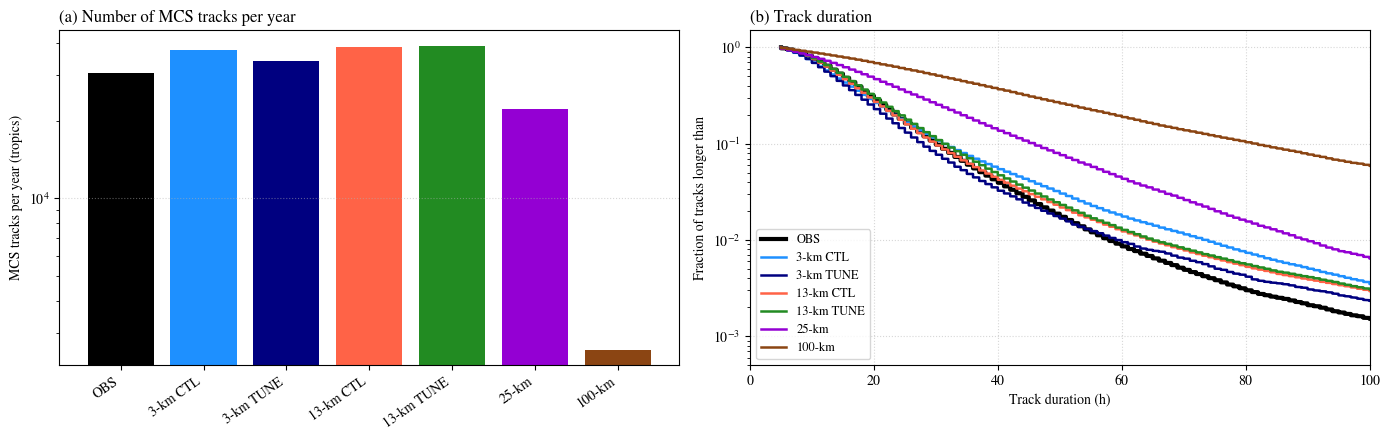

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# (a) Tracks per year: the number of tracks of a source divided by the time span of its record (so that a record of 19 months, or one that
# does not start on 1 January, is not under-counted)
ax = axes[0]
span_years = tracks.groupby('source')['start_basetime'].agg(lambda s: (s.max() - s.min()).total_seconds() / (365.25 * 86400))
tracks_per_year = (tracks.groupby('source').size() / span_years).reindex(SOURCE_ORDER)
ax.bar(range(len(SOURCE_ORDER)), tracks_per_year.values, color=[SOURCE_COLORS[s] for s in SOURCE_ORDER])
ax.set_xticks(range(len(SOURCE_ORDER)))
ax.set_xticklabels(SOURCE_ORDER, rotation=35, ha='right')
ax.set_yscale('log')
ax.set_ylabel(f'MCS tracks per year ({REGION})')
ax.set_title('(a) Number of MCS tracks per year', loc='left')
ax.grid(True, axis='y', alpha=0.5, linestyle=':')

# (b) Distribution of the track duration: a line per source (survival function, 1 - CDF)
ax = axes[1]
for key, cfg in SOURCES.items():
    d = np.sort(tracks.loc[tracks['source'] == cfg['label'], 'track_duration_h'].values)
    ax.plot(d, 1 - np.arange(1, len(d) + 1) / len(d), color=cfg['color'], linewidth=cfg['linewidth'], linestyle=cfg['linestyle'], label=cfg['label'])
ax.set_yscale('log')
ax.set_xlim(0, 100)
ax.set_ylim(5e-4, 1.5)
ax.set_xlabel('Track duration (h)')
ax.set_ylabel('Fraction of tracks longer than')
ax.set_title('(b) Track duration', loc='left')
ax.grid(True, alpha=0.5, linestyle=':')
ax.legend(fontsize=9)

fig.tight_layout()
figname = f'{figdir}mcs_trackstats_{REGION}_tracks_per_year_and_duration.png'
fig.savefig(figname, dpi=dpi, bbox_inches='tight', facecolor='w')
print(f'Figure saved: {figname}')
plt.show()

## Land / ocean classification and lifetime statistics
Every track is classified by the **lifetime minimum and maximum of `pf_landfrac`** (the land fraction of the precipitation feature, 0-1):

* **Land**: the lifetime minimum is above `LAND_MINFRAC` (the feature is never more than 10 % over water),
* **Ocean**: the lifetime maximum is below `OCEAN_MAXFRAC` (never more than 10 % over land).

The two subsets are disjoint; tracks in between (coastal) belong to neither. The filter keeps all time steps of the qualifying tracks.

In [8]:
# The columns that the analyses below use (the rest of the 69 columns is left out of the working table to save memory)
KEY_COLUMNS = ['source', 'local_track', 'relative_step', 'track_duration', 'track_duration_h', 'period', 'pf_landfrac',
               'start_split_cloudnumber', 'end_merge_cloudnumber', 'ccs_area', 'merge_ccs_area', 'split_ccs_area', 'core_area',
               'total_volrain', 'total_heavyvolrain']
DERIVED_COLUMNS = {'ccs_area_all', 'core_area_ratio', 'heavy_rain_ratio'}      # made below from other columns, not in the Parquet files
USED_COLUMNS = (set(KEY_COLUMNS) | set(max_vars) | set(min_vars) | set(mean_vars) | set(median_vars) | set(sum_vars) | set(comp_var_specs)
                | {'ccs_area', 'core_area'}) - DERIVED_COLUMNS
USED_COLUMNS = [c for c in sorted(USED_COLUMNS) if c in df.columns]
work = df[USED_COLUMNS]


def classify_land_ocean(df_ts, land_min=LAND_MINFRAC, ocean_max=OCEAN_MAXFRAC, landfrac_col='pf_landfrac'):
    """
    Split a time-step table into the land and the ocean tracks.

    Args:
        df_ts: DataFrame
            One row per track and time step, with the columns 'source', 'local_track' and landfrac_col.
        land_min: float (default: LAND_MINFRAC)
            A track is a land track if its lifetime-minimum land fraction is above this.
        ocean_max: float (default: OCEAN_MAXFRAC)
            A track is an ocean track if its lifetime-maximum land fraction is below this.
        landfrac_col: str (default: 'pf_landfrac')
            Column with the land fraction of the precipitation feature.

    Returns:
        df_land, df_ocean: DataFrame
            All time steps of the land tracks and of the ocean tracks, with a column 'surface' ('Land' / 'Ocean').
    """
    # Lifetime minimum and maximum of the land fraction of every track (NaN steps are skipped)
    lf = df_ts.groupby(['source', 'local_track'])[landfrac_col].agg(lf_min='min', lf_max='max').reset_index()
    land_ids = lf.loc[lf['lf_min'] > land_min, ['source', 'local_track']]
    ocean_ids = lf.loc[lf['lf_max'] < ocean_max, ['source', 'local_track']]
    # All time steps of the qualifying tracks
    df_land = df_ts.merge(land_ids, on=['source', 'local_track'])
    df_ocean = df_ts.merge(ocean_ids, on=['source', 'local_track'])
    df_land['surface'] = 'Land'
    df_ocean['surface'] = 'Ocean'
    return df_land, df_ocean


df_tracks_l, df_tracks_o = classify_land_ocean(work)

# Tracks per source and surface
rows = []
for cfg in SOURCES.values():
    label = cfg['label']
    n_all = work.loc[work['source'] == label, 'local_track'].nunique()
    n_land = df_tracks_l.loc[df_tracks_l['source'] == label, 'local_track'].nunique()
    n_ocean = df_tracks_o.loc[df_tracks_o['source'] == label, 'local_track'].nunique()
    rows.append({'source': label, 'all tracks': n_all, 'land tracks': n_land, 'ocean tracks': n_ocean,
                 'land %': f'{n_land / n_all:.1%}', 'ocean %': f'{n_ocean / n_all:.1%}'})
print(f'Land / ocean classification (land: lifetime-min pf_landfrac > {LAND_MINFRAC}; ocean: lifetime-max < {OCEAN_MAXFRAC})')
display(pd.DataFrame(rows).set_index('source'))

Land / ocean classification (land: lifetime-min pf_landfrac > 0.9; ocean: lifetime-max < 0.1)


,all tracks,land tracks,ocean tracks,land %,ocean %
source,,,,,
OBS,337321,80960,146452,24.0%,43.4%
3-km CTL,413609,105510,207669,25.5%,50.2%
3-km TUNE,54010,11986,26139,22.2%,48.4%
13-km CTL,425747,111210,227030,26.1%,53.3%
13-km TUNE,430223,96531,234315,22.4%,54.5%
25-km,66786,27036,23261,40.5%,34.8%
100-km,30998,11133,11443,35.9%,36.9%


### Derived variables and one row per track
`ccs_area_all` is the cloud-shield area including merged and split systems, `core_area_ratio` the convective core fraction of the cloud
shield and `heavy_rain_ratio` the heavy-rain share of the rain volume. Every variable of the lists in the Configuration gives a column
`{variable}_lt_{operation}` (max, min, mean, median, sum over the life of the track).

In [9]:
# Derived variables of the time-step tables (division by zero gives inf: replaced by NaN)
for _df in (df_tracks_l, df_tracks_o):
    _df['ccs_area_all'] = _df['ccs_area'] + _df['merge_ccs_area'] + _df['split_ccs_area']
    _df['core_area_ratio'] = _df['core_area'] / _df['ccs_area']
    _df['heavy_rain_ratio'] = _df['total_heavyvolrain'] / _df['total_volrain']
    _df.replace([np.inf, -np.inf], np.nan, inplace=True)


def compute_lifetime_stats(df_ts, max_vars, min_vars, mean_vars, median_vars, sum_vars=None):
    """
    Reduce a time-step table to one row per (source, local_track).

    Args:
        df_ts: DataFrame
            Time-step table with 'source', 'local_track', 'track_duration_h', 'period', 'surface' and the variables below.
        max_vars, min_vars, mean_vars, median_vars, sum_vars: list of str
            Variables that get the maximum, minimum, mean, median or sum over the life of the track (columns {var}_lt_max ... {var}_lt_sum);
            variables that the table does not have are skipped.

    Returns:
        df_lt: DataFrame
            One row per track.
    """
    sum_vars = sum_vars or []

    def present(var_list):
        return [v for v in var_list if v in df_ts.columns]

    # One named aggregation per variable and operation
    agg = {'track_duration_h': ('track_duration_h', 'first'), 'period': ('period', 'first'), 'surface': ('surface', 'first'),
           **{f'{c}_lt_max': (c, 'max') for c in present(max_vars)},
           **{f'{c}_lt_min': (c, 'min') for c in present(min_vars)},
           **{f'{c}_lt_mean': (c, 'mean') for c in present(mean_vars)},
           **{f'{c}_lt_median': (c, 'median') for c in present(median_vars)},
           **{f'{c}_lt_sum': (c, 'sum') for c in present(sum_vars)}}
    return df_ts.groupby(['source', 'local_track'], sort=False).agg(**agg).reset_index()


df_lt_l = compute_lifetime_stats(df_tracks_l, max_vars, min_vars, mean_vars, median_vars, sum_vars)
df_lt_o = compute_lifetime_stats(df_tracks_o, max_vars, min_vars, mean_vars, median_vars, sum_vars)
df_lt_all = pd.concat([df_lt_l, df_lt_o], ignore_index=True)

# Check: the land and ocean track sets must be disjoint
overlap = set(zip(df_lt_l['source'], df_lt_l['local_track'])) & set(zip(df_lt_o['source'], df_lt_o['local_track']))
print(f'Land tracks {len(df_lt_l):,}, ocean tracks {len(df_lt_o):,}; tracks in both sets: {len(overlap)} (must be 0)')
display(df_lt_all.groupby(['source', 'surface']).size().unstack().reindex(SOURCE_ORDER).rename_axis(None, axis=1))

Land tracks 444,366, ocean tracks 876,309; tracks in both sets: 0 (must be 0)


,Land,Ocean
source,,
OBS,80960,146452
3-km CTL,105510,207669
3-km TUNE,11986,26139
13-km CTL,111210,227030
13-km TUNE,96531,234315
25-km,27036,23261
100-km,11133,11443


## Box-whisker plots of the MCS lifetime statistics
One panel per lifetime statistic, land and ocean on the x axis and one box per source (the colors of the Configuration). The box is the
interquartile range with the median (notched), the whiskers span `box_whis` (default 5th-95th percentile), the white dot is the mean, and the
legend gives the number of tracks of every source.

Saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/mcs_lifetime_stats_land_ocean_boxplot_tropics.png


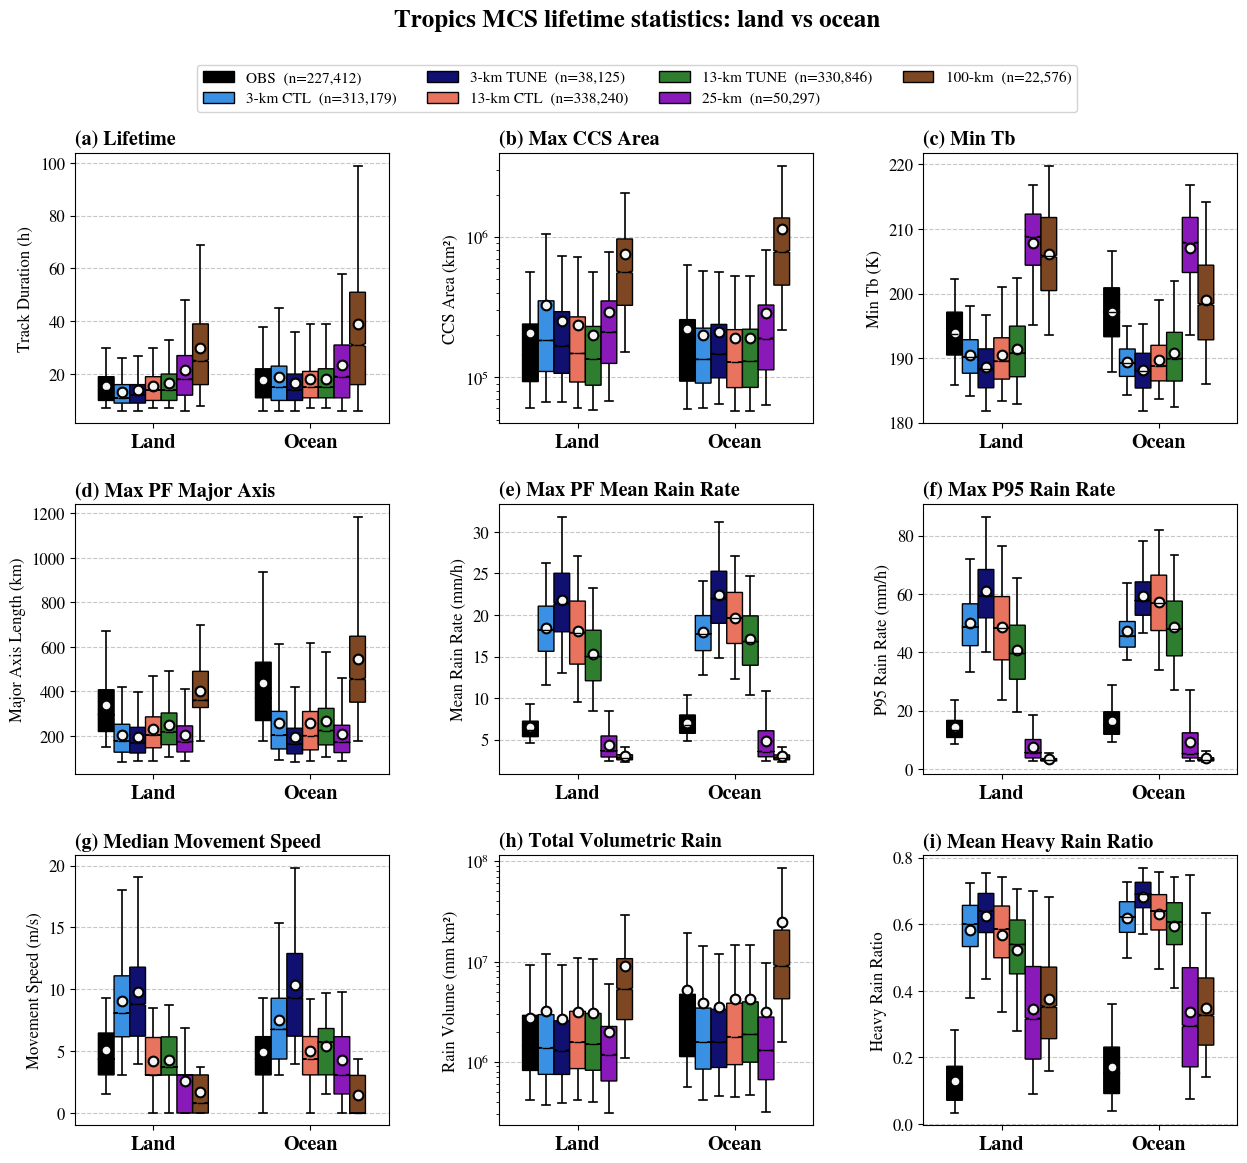

In [10]:
def plot_boxplots(df_lt, variables, var_labels=None, source_order=None, source_colors=None, surface_order=None, whis=(5, 95),
                  showmean=True, notch=False, showcaps=True, figsize=None, figname=None, xtick_rotation=0, box_width=0.55,
                  panel_titles=None, yscale=None, suptitle=None, fontsize=12, hspace=0.4, wspace=0.35, legend_ncol=None):
    """
    M x N panels of grouped box plots of the lifetime statistics: x = surface (land / ocean), one box per source.

    Args:
        df_lt: DataFrame
            One row per track with the columns 'surface', 'source' and the variables.
        variables: list of lists of str
            The variable of every panel [row][column]; None or a missing column leaves the panel empty.
        var_labels: dict (default: None)
            {column: y label}.
        source_order, source_colors, surface_order: list, dict, list (default: SOURCE_ORDER, SOURCE_COLORS, SURFACE_ORDER)
            Order of the boxes, their colors and the order of the surfaces.
        whis: tuple (default: (5, 95))
            Percentiles of the whiskers.
        showmean, notch, showcaps: bool (default: True, False, True)
            Mean marker, notched boxes, whisker caps.
        figsize: tuple (default: None = 4.5 inch per column and 4 inch per row)
            Figure size.
        figname: str (default: None)
            File to save.
        xtick_rotation, box_width, fontsize, hspace, wspace: float
            Cosmetics.
        panel_titles: list of lists of str (default: None)
            Panel titles.
        yscale: list of lists of str (default: None = linear)
            'linear' or 'log' of every panel.
        suptitle: str (default: None)
            Figure title.
        legend_ncol: int (default: None = one column per source)
            Columns of the figure legend.

    Returns:
        fig: Figure
    """
    import seaborn as sns
    source_order = source_order or SOURCE_ORDER
    source_colors = source_colors or SOURCE_COLORS
    surface_order = surface_order or SURFACE_ORDER
    var_labels = var_labels or {}
    legend_ncol = legend_ncol or min(len(source_order), 4)
    nrows, ncols = len(variables), max(len(row) for row in variables)
    figsize = figsize or (ncols * 4.5, nrows * 4)
    mpl.rcParams['font.size'] = fontsize
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    # Number of tracks per source (all surfaces), for the legend
    track_counts = {src: int((df_lt['source'] == src).sum()) for src in source_order}
    mean_props = dict(marker='o', markersize=7, markerfacecolor='whitesmoke', markeredgecolor='k', markeredgewidth=1.5, zorder=4)
    median_props = dict(color='k', linewidth=1, zorder=5)
    handles = labels = None
    # Loop over the panels: one grouped box plot each
    for ri, row_vars in enumerate(variables):
        for ci in range(ncols):
            ax = axes[ri][ci]
            var = row_vars[ci] if ci < len(row_vars) else None
            if var is None or var not in df_lt.columns:
                ax.set_visible(False)
                continue
            sns.boxplot(data=df_lt[df_lt[var].notna()], x='surface', y=var, hue='source', order=surface_order, hue_order=source_order,
                        palette=source_colors, dodge=True, width=box_width, whis=list(whis), showfliers=False, notch=notch,
                        medianprops=median_props, whiskerprops=dict(color='black', linewidth=1.2), capprops=dict(color='black', linewidth=1.2),
                        showcaps=showcaps, showmeans=showmean, meanprops=mean_props, ax=ax)
            if panel_titles and ri < len(panel_titles) and ci < len(panel_titles[ri]):
                ax.set_title(panel_titles[ri][ci], loc='left', fontweight='bold')
            ax.set_yscale(yscale[ri][ci] if yscale and ri < len(yscale) and ci < len(yscale[ri]) else 'linear')
            ax.set_ylabel(var_labels.get(var, var))
            ax.set_xlabel('')
            ax.grid(axis='y', ls='--', alpha=0.7)
            ax.tick_params(axis='both', labelsize=fontsize)
            ax.tick_params(axis='x', rotation=xtick_rotation)
            for lbl in ax.get_xticklabels():
                lbl.set_fontweight('bold')
                lbl.set_fontsize(fontsize * 1.2)
            # The legend is made once for the figure: keep the handles of the first panel and remove the legend of every axes
            if handles is None:
                handles, labels = ax.get_legend_handles_labels()
            if ax.get_legend() is not None:
                ax.get_legend().remove()
    fig.subplots_adjust(top=0.92 if (handles or suptitle) else 1.0, hspace=hspace, wspace=wspace)
    if handles is not None:
        fig.legend(handles, [f'{lbl}  (n={track_counts.get(lbl, 0):,})' for lbl in labels], loc='upper center', bbox_to_anchor=(0.5, 1.0),
                   ncol=legend_ncol, frameon=True, framealpha=0.85, fontsize=fontsize - 1)
    if suptitle is not None:
        fig.suptitle(suptitle, y=1.04, fontsize=fontsize * 1.5, fontweight='bold')
    if figname:
        fig.savefig(figname, dpi=dpi, bbox_inches='tight', facecolor='w')
        print(f'Saved: {figname}')
    return fig


def save_figure(fig, stem):
    """Save a figure in every format of FIGURE_FORMATS as {figdir}{stem}.{format}."""
    for fmt in FIGURE_FORMATS:
        path = f'{figdir}{stem}.{fmt}'
        fig.savefig(path, dpi=dpi, bbox_inches='tight', facecolor='w')
        print(f'Saved: {path}')


fig = plot_boxplots(df_lt_all, lt_variables, var_labels=lt_labels, suptitle=f'{REGION.capitalize()} MCS lifetime statistics: land vs ocean',
                    yscale=lt_yscale, box_width=box_width, whis=box_whis, notch=box_notch, panel_titles=lt_panel_titles,
                    figsize=box_figsize, hspace=0.3, wspace=0.35)
save_figure(fig, f'mcs_lifetime_stats_land_ocean_boxplot_{REGION}')
plt.show()

## Significance test: each model against the observation
For every lifetime statistic, surface and model: the **mean % difference** relative to the reference source (`REF_SOURCE`) and a two-sided
**Mann-Whitney U** test (the variables are skewed, so no normality is assumed).

| aspect | choice |
| --- | --- |
| % difference | `(mean_model - mean_ref) / abs(mean_ref) x 100` |
| % difference of a brightness temperature (`mintb` variables) | `(mean_model - mean_ref) / (P90_ref - P10_ref) x 100`: the absolute Tb is far from zero, so the difference is scaled by the 10-90 % range of the reference |
| significance | Mann-Whitney U, `ALPHA`; **✘ is appended when the difference is not significant** |
| smallest group | `MIN_N` tracks, otherwise the cell shows `–` |

Rows are the statistics; the first column shows the mean of the reference, the other columns one model each with two lines, `L:` for land
and `O:` for ocean.

In [11]:
from scipy import stats
from IPython.display import HTML


def fmt_mean(x):
    """Adaptive precision of a mean value (no units): thousands separator for >= 100, one decimal for >= 1, two significant digits below."""
    if x is None or np.isnan(x):
        return '–'
    if abs(x) >= 100:
        return f'{x:,.0f}'
    if abs(x) >= 1:
        return f'{x:,.1f}'
    return f'{x:.2g}'


def compute_sig_table(df_lt, stat_vars, ref_label, cmp_labels, surfaces, alpha, min_n):
    """
    Mean % difference and Mann-Whitney U significance of every comparison source against the reference, per variable and surface.

    Args:
        df_lt: DataFrame
            One row per track with 'source', 'surface' and the variables.
        stat_vars: dict
            {column: row label}.
        ref_label: str
            'source' value of the reference.
        cmp_labels: list of str
            'source' values of the compared sources.
        surfaces: list of (surface value, short label)
            For example [('Land', 'L'), ('Ocean', 'O')].
        alpha: float
            Significance level.
        min_n: int
            Smallest number of tracks per group.

    Returns:
        data: dict
            data[var][ref_label][surface] = reference mean; data[var][cmp_label][surface] = (text such as '+12%', is_significant or None).
    """
    data = {}
    for var in stat_vars:
        data[var] = {ref_label: {}}
        for surf, _ in surfaces:
            ref = df_lt[(df_lt['source'] == ref_label) & (df_lt['surface'] == surf)][var].dropna()
            ref_mean = ref.mean() if len(ref) >= min_n else np.nan
            data[var][ref_label][surf] = ref_mean
            # Loop over the compared sources
            for cmp_label in cmp_labels:
                data[var].setdefault(cmp_label, {})
                cmp = df_lt[(df_lt['source'] == cmp_label) & (df_lt['surface'] == surf)][var].dropna()
                if len(ref) < min_n or len(cmp) < min_n or ref_mean == 0 or np.isnan(ref_mean):
                    data[var][cmp_label][surf] = ('N/A', None)
                    continue
                # Tb is scaled by the 10-90 % range of the reference, the other variables by the reference mean
                if 'mintb' in var:
                    pct = (cmp.mean() - ref_mean) / abs(ref.quantile(0.90) - ref.quantile(0.10)) * 100
                else:
                    pct = (cmp.mean() - ref_mean) / abs(ref_mean) * 100
                _, p = stats.mannwhitneyu(cmp, ref, alternative='two-sided')
                data[var][cmp_label][surf] = (f'{pct:+.0f}%', bool(p < alpha))
    return data


TABLE_CSS = """
<style>
.sigtab { border-collapse: collapse; font-size: 12px; font-family: Arial, sans-serif; margin-bottom: 20px; }
.sigtab th { background-color: #4472C4; color: white; font-weight: bold; padding: 6px 10px; border: 1px solid #ccc; text-align: center; }
.sigtab td { border: 1px solid #ccc; padding: 5px 8px; text-align: center; vertical-align: top; line-height: 1.6; background-color: #ffffff; }
.sigtab td.varname { text-align: left; font-weight: bold; color: #000000; white-space: nowrap; }
.pct-pos { color: #c0392b; }   /* the model is above the reference */
.pct-neg { color: #2471a3; }   /* the model is below the reference */
.pct-na { color: #999; }
</style>
"""


def build_html_table(data, stat_vars, ref_label, cmp_labels, surfaces, title):
    """
    Render the output of compute_sig_table as an HTML table: reference column (means), then one column per compared source.

    Args:
        data: dict
            Output of compute_sig_table.
        stat_vars: dict
            {column: row label (HTML allowed)}.
        ref_label, cmp_labels, surfaces:
            As in compute_sig_table; the labels are the column headers.
        title: str
            Heading of the table.

    Returns:
        html: str
    """
    html = TABLE_CSS + f'<h3 style="font-family:Arial;color:#000">{title}</h3>\n<table class="sigtab"><thead><tr><th>Variable</th>'
    for lbl in [ref_label] + cmp_labels:
        html += f'<th>{lbl}</th>'
    html += '</tr></thead><tbody>\n'
    # One row per statistic: the reference means, then % difference and significance per surface
    for var, row_label in stat_vars.items():
        html += f'<tr><td class="varname">{row_label}</td>'
        html += '<td>' + '<br>'.join(f'{short}: {fmt_mean(data[var][ref_label].get(surf, np.nan))}' for surf, short in surfaces) + '</td>'
        for cmp_label in cmp_labels:
            lines = []
            for surf, short in surfaces:
                text, sig = data[var][cmp_label].get(surf, ('N/A', None))
                if text == 'N/A':
                    lines.append(f'{short}: <span class="pct-na">–</span>')
                else:
                    cls = 'pct-pos' if text.startswith('+') else 'pct-neg'
                    lines.append(f'{short}: <span class="{cls}">{text}</span>' + ('' if sig else f' {NONSIG}'))
            html += '<td>' + '<br>'.join(lines) + '</td>'
        html += '</tr>\n'
    return html + '</tbody></table>'


ref_label = SOURCES[REF_SOURCE]['label']
cmp_labels = [cfg['label'] for key, cfg in SOURCES.items() if key != REF_SOURCE]
sig_data = compute_sig_table(df_lt_all, STAT_VARS, ref_label, cmp_labels, SURFACES, ALPHA, MIN_N)
sig_title = (f'{REGION.capitalize()} MCS: mean % difference vs {ref_label} (Mann-Whitney U, α={ALPHA}; {NONSIG} = not significant; '
             f'L = land, O = ocean; the {ref_label} column shows the mean values)')
sig_html = build_html_table(sig_data, STAT_VARS, ref_label, cmp_labels, SURFACES, sig_title)
display(HTML(sig_html))
html_file = f'{figdir}Table_{REGION}_mcs_trackstats_land_ocean.html'
with open(html_file, 'w', encoding='utf-8') as f:
    f.write(sig_html)
print(f'Saved: {html_file}')

Variable,OBS,3-km CTL,3-km TUNE,13-km CTL,13-km TUNE,25-km,100-km
Lifetime(h),L: 15.4O: 17.9,L: -14%O: +5%,L: -10%O: -7%,L: +1% ✘O: +1%,L: +8%O: +2%,L: +39%O: +32%,L: +95%O: +119%
Max CCS Area(km2),"L: 206,142O: 221,690",L: +57%O: -10%,L: +23%O: -6% ✘,L: +15%O: -14%,L: -3%O: -14%,L: +42%O: +29%,L: +268%O: +413%
Min Tb(K),L: 194O: 197,L: -26%O: -54%,L: -41%O: -62%,L: -27%O: -51%,L: -19%O: -45%,L: +112%O: +69%,L: +98%O: +13%
Max PF Major Axis(km),L: 337O: 439,L: -39%O: -41%,L: -42%O: -55%,L: -31%O: -42%,L: -26%O: -39%,L: -40%O: -52%,L: +19%O: +24%
Max Mean Rain Rate(mm h-1),L: 6.5O: 7.0,L: +186%O: +156%,L: +237%O: +218%,L: +179%O: +180%,L: +137%O: +143%,L: -32%O: -31%,L: -54%O: -58%
Max P95 Rain Rate(mm h-1),L: 14.3O: 16.5,L: +250%O: +186%,L: +326%O: +260%,L: +241%O: +246%,L: +184%O: +195%,L: -47%O: -45%,L: -77%O: -78%
Median Move. Speed(m s-1),L: 5.1O: 5.0,L: +79%O: +51%,L: +94%O: +109%,L: -17%O: +1%,L: -15%O: +9%,L: -49%O: -14%,L: -67%O: -71%
Total Rain Volume(mm km2),"L: 2,743,528O: 5,172,444",L: +16%O: -25%,L: -3%O: -32%,L: +15%O: -19%,L: +12%O: -18%,L: -28%O: -39%,L: +233%O: +375%
Heavy Rain Ratio,L: 0.13O: 0.17,L: +347%O: +263%,L: +377%O: +301%,L: +335%O: +269%,L: +301%O: +249%,L: +164%O: +98%,L: +188%O: +104%


Saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/Table_tropics_mcs_trackstats_land_ocean.html


## Composite life cycle of the MCSs
The time evolution of MCS properties since initiation, composited over the tracks of a **lifetime bin** (a half-open interval `[lo, hi)` of the
track duration in hours; the bins are in `dur_bins`), separately for land and ocean tracks. Only tracks with a **natural start and end** are used:
they did not split off another track (`start_split_cloudnumber` is NaN) and did not merge into another one (`end_merge_cloudnumber` is NaN).

Two ways of compositing (`COMPOSITE_MODES`):

* **interpolated**: every track is stretched in time onto the same number of steps, the centre of its duration bin (linear interpolation of its
  valid values), so that every step of the composite has all the tracks of the bin: no drop-off of the tail.
* **raw**: the composite on the relative time axis in hours since initiation: the number of tracks falls at the end, because the shorter tracks
  of the bin have ended.

A bin with fewer than `MIN_TRACKS_COMPOSITE` tracks is not composited.

In [12]:
def interpolate_valid_tracks(df_ts, var, n_common, time_col='relative_step', track_col='local_track'):
    """
    Stretch every track of a table onto n_common steps: the valid values of the track (NaN steps dropped) are linearly interpolated onto
    a uniform grid, as np.interp does one track at a time. Tracks with the same number of valid values are interpolated together.

    Args:
        df_ts: DataFrame
            Time-step table of the tracks to composite (one source).
        var: str
            Column to interpolate.
        n_common: int
            Number of steps of the common time axis.
        time_col, track_col: str
            Columns of the time step and of the track id.

    Returns:
        matrix: ndarray [n_tracks_used, n_common]
            One interpolated series per track (tracks with fewer than 2 valid values are left out).
    """
    d = df_ts[[track_col, time_col, var]].dropna(subset=[var]).sort_values([track_col, time_col])
    values = d[var].to_numpy(dtype=float)
    track_ids = d[track_col].to_numpy()
    # Boundaries of the tracks in the sorted array and the number of valid values of every track
    first = np.r_[0, np.flatnonzero(track_ids[1:] != track_ids[:-1]) + 1]
    counts = np.diff(np.r_[first, len(values)])
    out = []
    x_new = np.linspace(0.0, 1.0, n_common)
    # Loop over the distinct numbers of valid values m: all tracks with m values are interpolated in one operation
    for m in np.unique(counts[counts >= 2]):
        starts = first[counts == m]
        block = values[starts[:, None] + np.arange(m)[None, :]]               # [tracks with m values, m]
        pos = x_new * (m - 1)                                                   # position on the m-point grid
        i0 = np.minimum(np.floor(pos).astype(int), m - 2)
        frac = pos - i0
        out.append(block[:, i0] * (1 - frac) + block[:, i0 + 1] * frac)
    return np.vstack(out) if out else np.empty((0, n_common))


def composite_track_evolution(df_ts, var, duration_range, interpolate=False, min_tracks=1, time_col='relative_step',
                              duration_col='track_duration', track_col='local_track'):
    """
    Composite time evolution of a variable over the tracks whose duration is in [lo, hi).

    Args:
        df_ts: DataFrame
            Time-step table of ONE source (and surface).
        var: str
            Column to composite.
        duration_range: tuple (lo, hi)
            Half-open interval of the track duration [h] (the duration column holds the number of hourly steps).
        interpolate: bool (default: False)
            True: stretch every track onto round((lo + hi) / 2) steps first (see interpolate_valid_tracks); False: the raw relative time.
        min_tracks: int (default: 1)
            Fewer tracks in the bin: None is returned.
        time_col, duration_col, track_col: str
            Column names.

    Returns:
        result: dict or None
            time, mean, median, q25, q75 (the 25th and 75th percentile), n (tracks contributing at every step), n_tracks (tracks in the bin),
            duration_range.
    """
    lo, hi = duration_range
    sub = df_ts[(df_ts[duration_col] >= lo) & (df_ts[duration_col] < hi)]
    n_tracks = sub[track_col].nunique()
    if n_tracks < min_tracks or n_tracks == 0:
        return None
    # Interpolated: a matrix [tracks, steps]; raw: the statistics at every relative time step
    if interpolate:
        n_common = int(round((lo + hi) / 2))
        matrix = interpolate_valid_tracks(sub, var, n_common, time_col, track_col)
        if matrix.shape[0] == 0:
            return None
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', category=RuntimeWarning)
            q25, median, q75 = np.nanpercentile(matrix, [25, 50, 75], axis=0)
            return dict(time=np.arange(n_common), mean=np.nanmean(matrix, axis=0), median=median, q25=q25, q75=q75,
                        n=np.sum(~np.isnan(matrix), axis=0), n_tracks=matrix.shape[0], duration_range=duration_range)
    grp = sub.groupby(time_col)[var]
    q = grp.quantile([0.25, 0.5, 0.75]).unstack()
    return dict(time=q.index.to_numpy(), mean=grp.mean().to_numpy(), median=q[0.5].to_numpy(), q25=q[0.25].to_numpy(), q75=q[0.75].to_numpy(),
                n=grp.count().to_numpy(), n_tracks=n_tracks, duration_range=duration_range)


def composite_track_evolution_loop(df_ts, var, duration_range, time_col='relative_step', duration_col='track_duration', track_col='local_track'):
    """
    The interpolated composite, one track at a time with np.interp (the straightforward version; used to check composite_track_evolution).

    Args:
        df_ts, var, duration_range, time_col, duration_col, track_col: see composite_track_evolution.

    Returns:
        matrix: ndarray [n_tracks_used, n_common]
    """
    lo, hi = duration_range
    sub = df_ts[(df_ts[duration_col] >= lo) & (df_ts[duration_col] < hi)]
    n_common = int(round((lo + hi) / 2))
    common_x = np.linspace(0, 1, n_common)
    rows = []
    # Loop over the tracks: the valid values on a uniform grid
    for _, grp in sub.groupby(track_col, sort=False):
        y = grp.sort_values(time_col)[var].to_numpy(dtype=float)
        y = y[~np.isnan(y)]
        if len(y) >= 2:
            rows.append(np.interp(common_x, np.linspace(0, 1, len(y)), y))
    return np.vstack(rows) if rows else np.empty((0, n_common))


# Check: the fast interpolation gives the same matrix as the track-by-track loop (observation, land tracks, one bin, one variable);
# the order of the rows may differ, so the rows are sorted before the comparison
_test = df_tracks_l[df_tracks_l['source'] == ref_label]
_test = _test[(np.isnan(_test['start_split_cloudnumber'])) & (np.isnan(_test['end_merge_cloudnumber']))]
_bin = dur_bins[1]
_t0 = time.time()
_fast = interpolate_valid_tracks(_test[(_test['track_duration'] >= _bin[0]) & (_test['track_duration'] < _bin[1])], 'ccs_area', int(round(sum(_bin) / 2)))
_t1 = time.time()
_slow = composite_track_evolution_loop(_test, 'ccs_area', _bin)
_t2 = time.time()
_fast_sorted = _fast[np.lexsort(_fast.T[::-1])]
_slow_sorted = _slow[np.lexsort(_slow.T[::-1])]
print(f'check on {ref_label} land tracks, bin {_bin} h, ccs_area: {_fast.shape[0]:,} tracks; fast {_t1 - _t0:.1f} s, loop {_t2 - _t1:.1f} s; '
      f'largest difference {np.abs(_fast_sorted - _slow_sorted).max():.2e} (relative to the largest value: '
      f'{np.abs(_fast_sorted - _slow_sorted).max() / np.abs(_slow_sorted).max():.1e}; same shape: {_fast.shape == _slow.shape})')
del _test, _fast, _slow, _fast_sorted, _slow_sorted

check on OBS land tracks, bin (10, 14) h, ccs_area: 13,907 tracks; fast 0.0 s, loop 2.9 s; largest difference 5.24e-10 (relative to the largest value: 3.4e-16; same shape: True)


### Compute the composites
For every mode, surface, variable (`comp_var_specs`), source and duration bin. The bin label uses an en dash, for example `10–14 h`.

In [13]:
def filter_nosplit(df_ts):
    """Keep the tracks that neither split off another track nor merge into another one (the start and the end are natural)."""
    return df_ts[np.isnan(df_ts['start_split_cloudnumber']) & np.isnan(df_ts['end_merge_cloudnumber'])]


surface_tables = {'Land': filter_nosplit(df_tracks_l), 'Ocean': filter_nosplit(df_tracks_o)}
print('Tracks with a natural start and end (land / ocean):')
display(pd.DataFrame({surf: tbl.drop_duplicates(['source', 'local_track']).groupby('source').size() for surf, tbl in surface_tables.items()})
        .reindex(SOURCE_ORDER).fillna(0).astype(int))

# composites[mode][surface][variable][source label][bin label] = result dict
composites = {}
t_start = time.time()
for mode in COMPOSITE_MODES:
    composites[mode] = {}
    for surf, tbl in surface_tables.items():
        composites[mode][surf] = {var: {} for var in comp_var_specs}
        # One table per source, filtered once
        for label in SOURCE_ORDER:
            tbl_src = tbl[tbl['source'] == label]
            for var in comp_var_specs:
                composites[mode][surf][var][label] = {}
                for lo, hi in dur_bins:
                    result = composite_track_evolution(tbl_src, var, (lo, hi), interpolate=(mode == 'interpolated'), min_tracks=MIN_TRACKS_COMPOSITE)
                    if result is not None:
                        composites[mode][surf][var][label][f'{lo}–{hi} h'] = result
        print(f'{mode:12s} {surf:5s}: done ({time.time() - t_start:.0f} s so far)')

# Tracks in every bin (the counts that the figures do not show)
rows = []
for mode in COMPOSITE_MODES[:1]:
    for surf in surface_tables:
        for label in SOURCE_ORDER:
            row = {'surface': surf, 'source': label}
            for lo, hi in dur_bins:
                res = composites[mode][surf][next(iter(comp_var_specs))][label].get(f'{lo}–{hi} h')
                row[f'{lo}–{hi} h'] = res['n_tracks'] if res else 0
            rows.append(row)
bin_counts = pd.DataFrame(rows).set_index(['surface', 'source'])
print(f'Tracks per duration bin (a bin with fewer than {MIN_TRACKS_COMPOSITE} tracks is not composited; the first variable, the first mode):')
display(bin_counts)
bin_counts.to_csv(f'{figdir}composite_tracks_per_bin_{REGION}.csv')

Tracks with a natural start and end (land / ocean):


,Land,Ocean
source,,
OBS,43658,54440
3-km CTL,48769,51120
3-km TUNE,5515,8065
13-km CTL,53964,88659
13-km TUNE,45001,90089
25-km,2646,2251
100-km,4124,2833


interpolated Land : done (4 s so far)


interpolated Ocean: done (11 s so far)


raw          Land : done (15 s so far)


raw          Ocean: done (21 s so far)
Tracks per duration bin (a bin with fewer than 20 tracks is not composited; the first variable, the first mode):


4–10 h  10–14 h  14–18 h  18–22 h  22–26 h  26–30 h
surface source                                                         
Land    OBS           4018    13907    10862     6710     3633     1930
        3-km CTL      9042    17850    10571     5642     2999     1238
        3-km TUNE      853     2001     1243      675      358      170
        13-km CTL     4559    14817    13791     9373     5820     2971
        13-km TUNE    2975    11237    11246     8076     5115     2872
        25-km           68      190      389      474      413      335
        100-km         175      439      540      571      460      267
Ocean   OBS           2973     9133    12396    10567     7249     4100
        3-km CTL      4553     9914    10744     9400     6430     3437
        3-km TUNE      951     1824     1881     1341      843      459
        13-km CTL     7064    23346    21145    14366     8774     5037
        13-km TUNE    6111    21299    20758    15529     9666     5878
        25-km           45      127      225      288      291      264
        100-km           0       33       96      159      225      237

### Composites by lifetime
One panel per variable (rows) and source (columns), one line per duration bin (the mean of the composite), for the land and for the ocean tracks
and for every mode.

Saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/composite_by_lifetime_land_interpolated_tropics.png


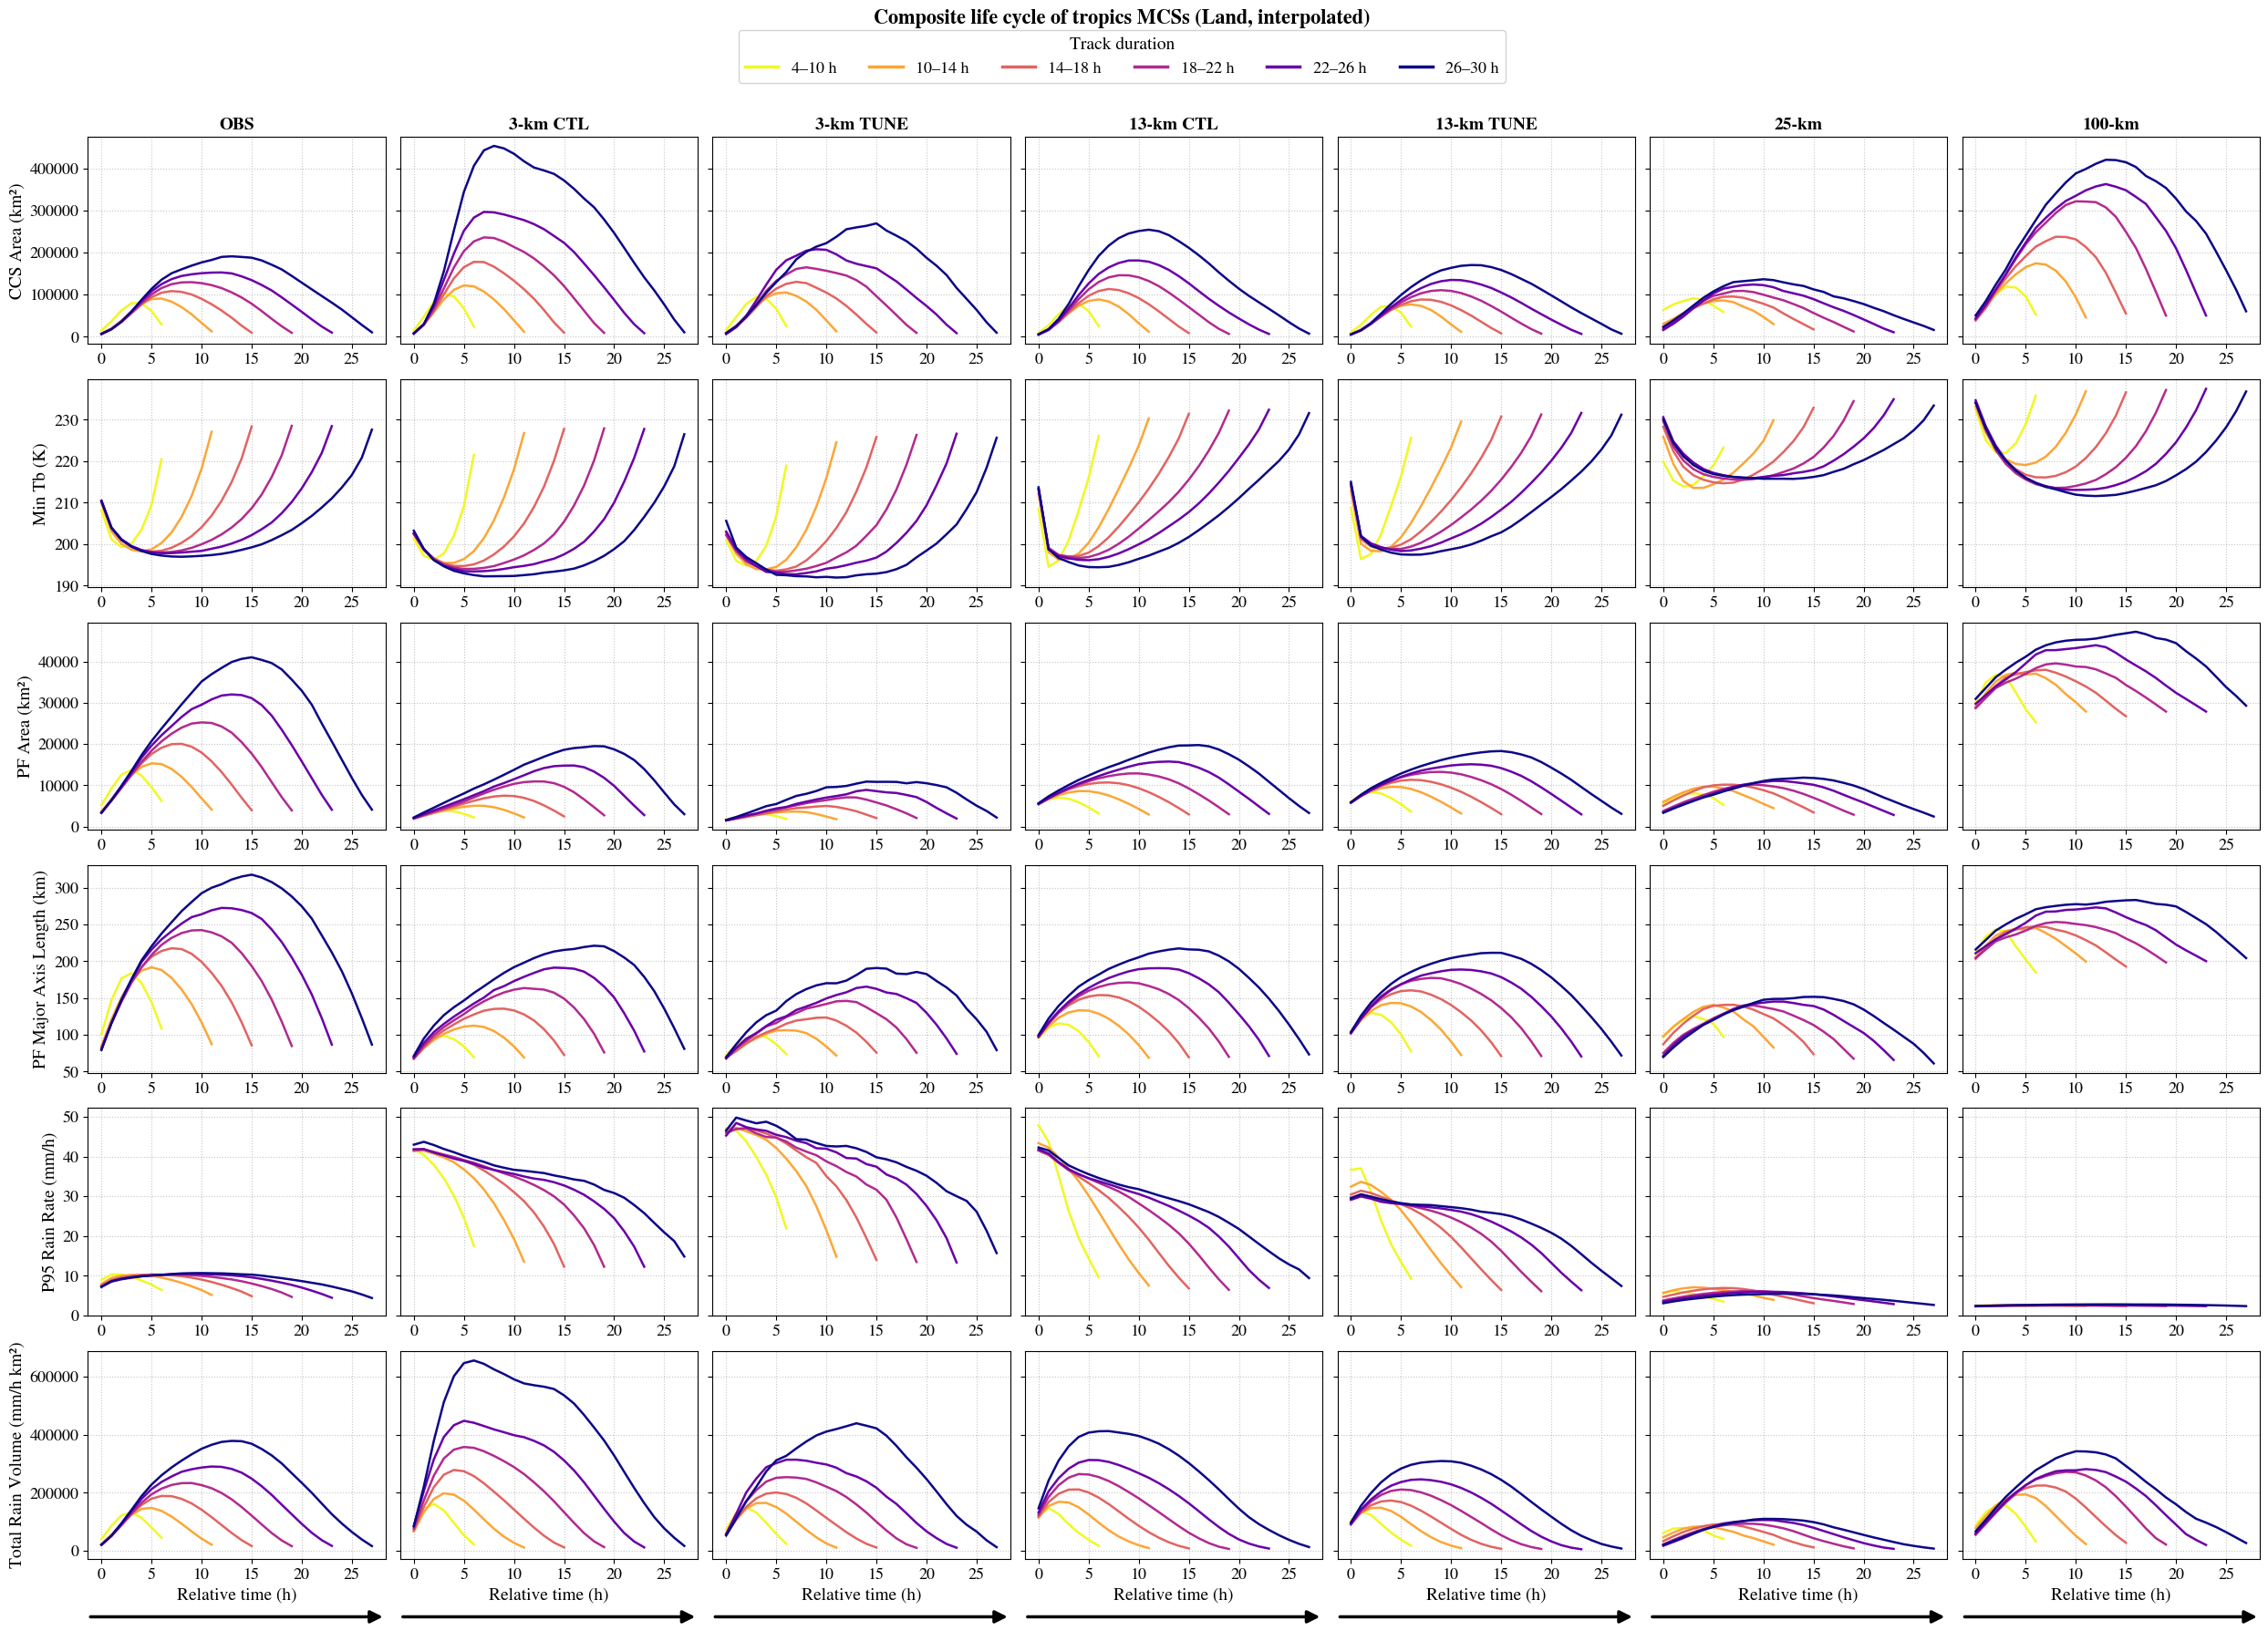

Saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/composite_by_lifetime_ocean_interpolated_tropics.png


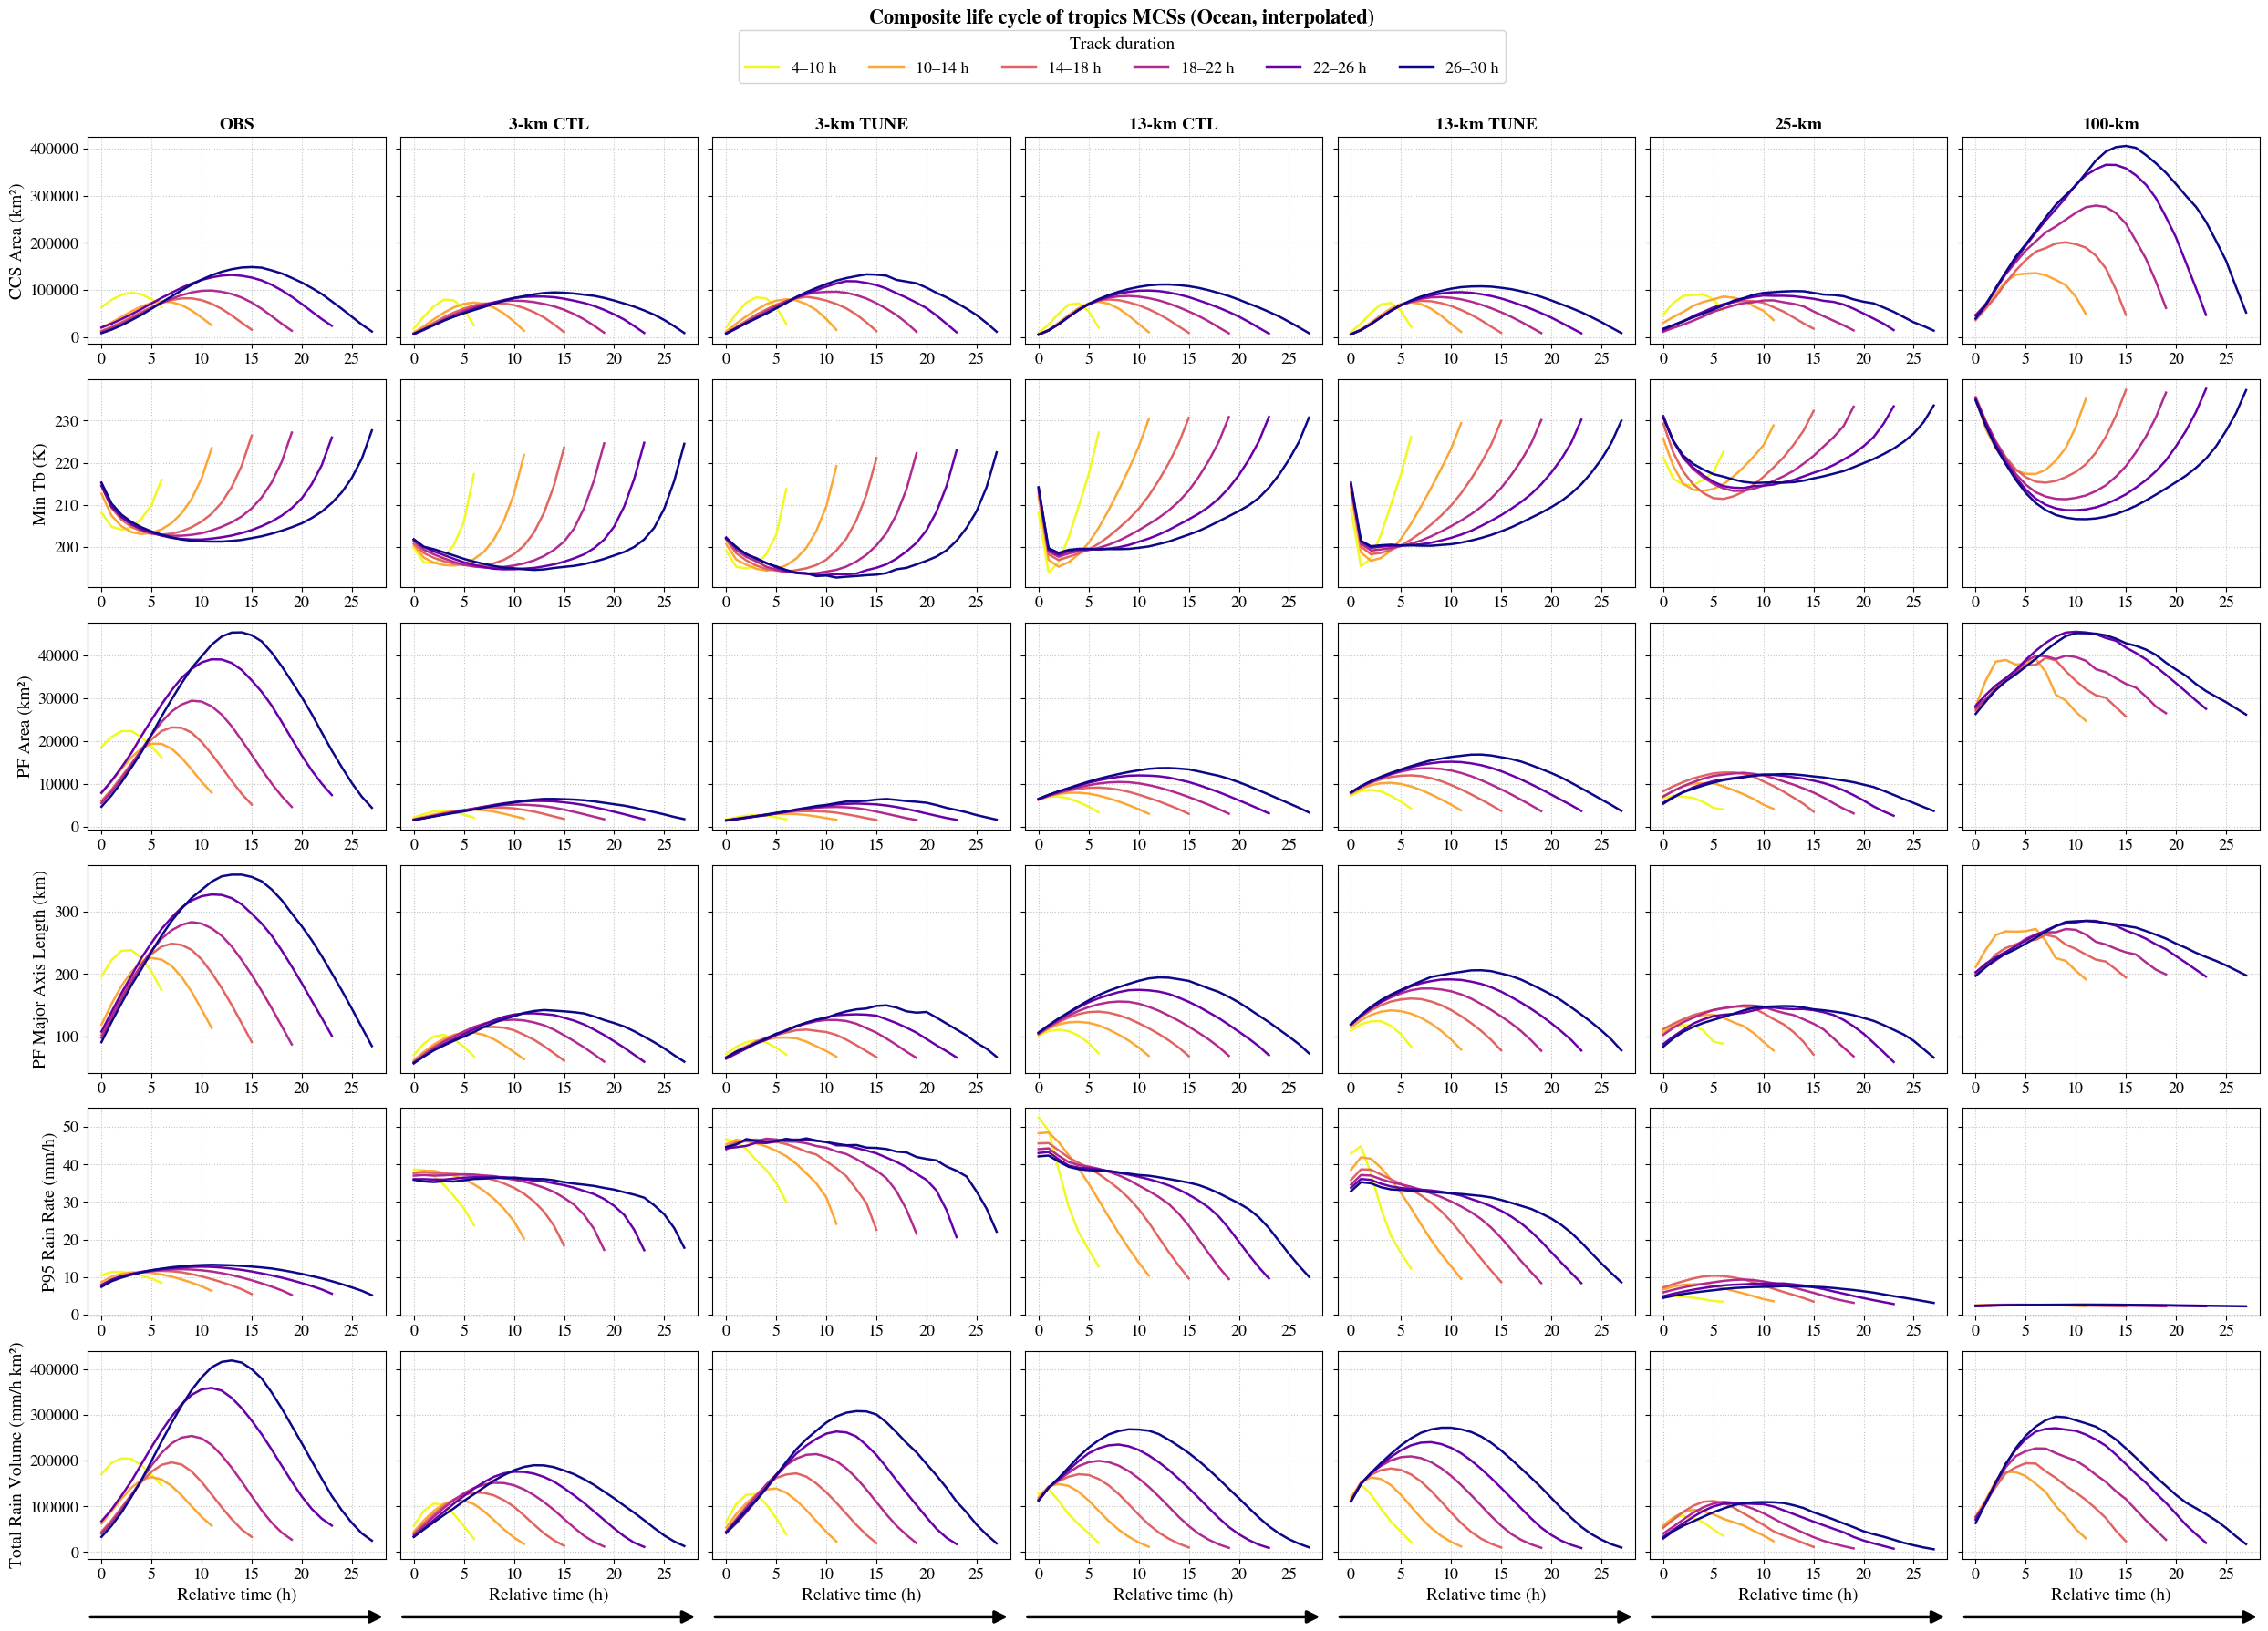

Saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/composite_by_lifetime_land_raw_tropics.png


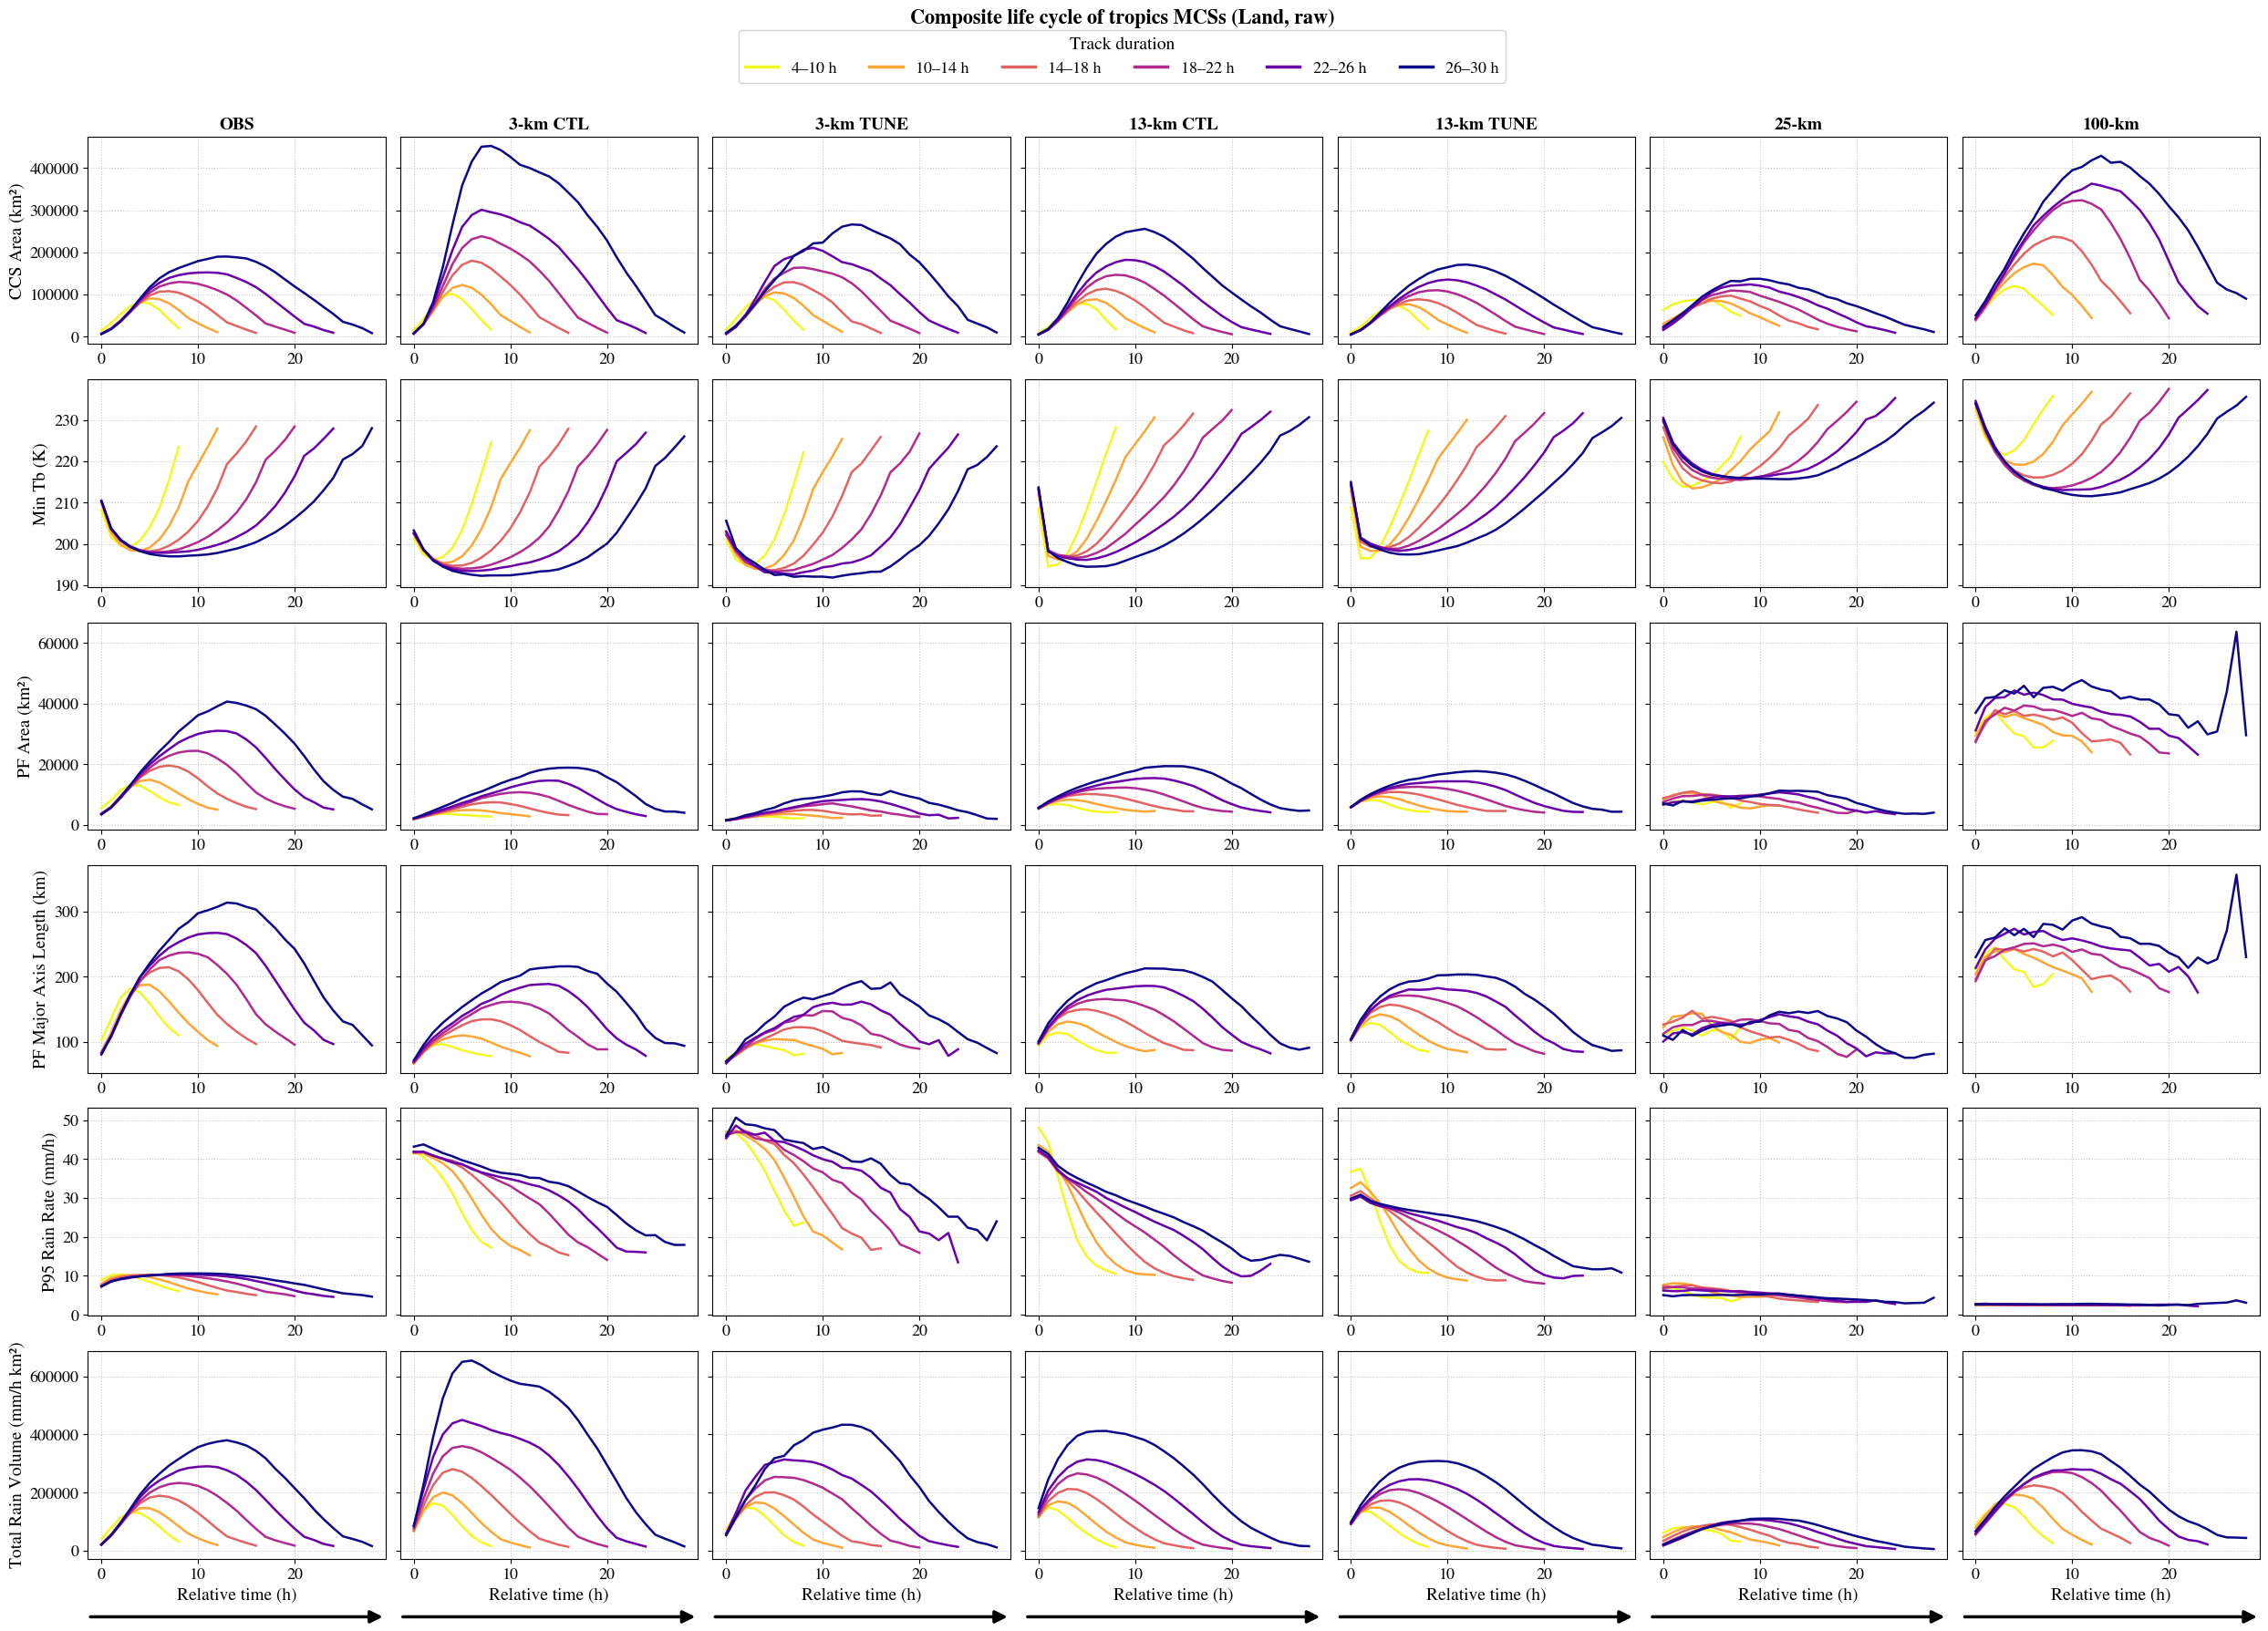

Saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/composite_by_lifetime_ocean_raw_tropics.png


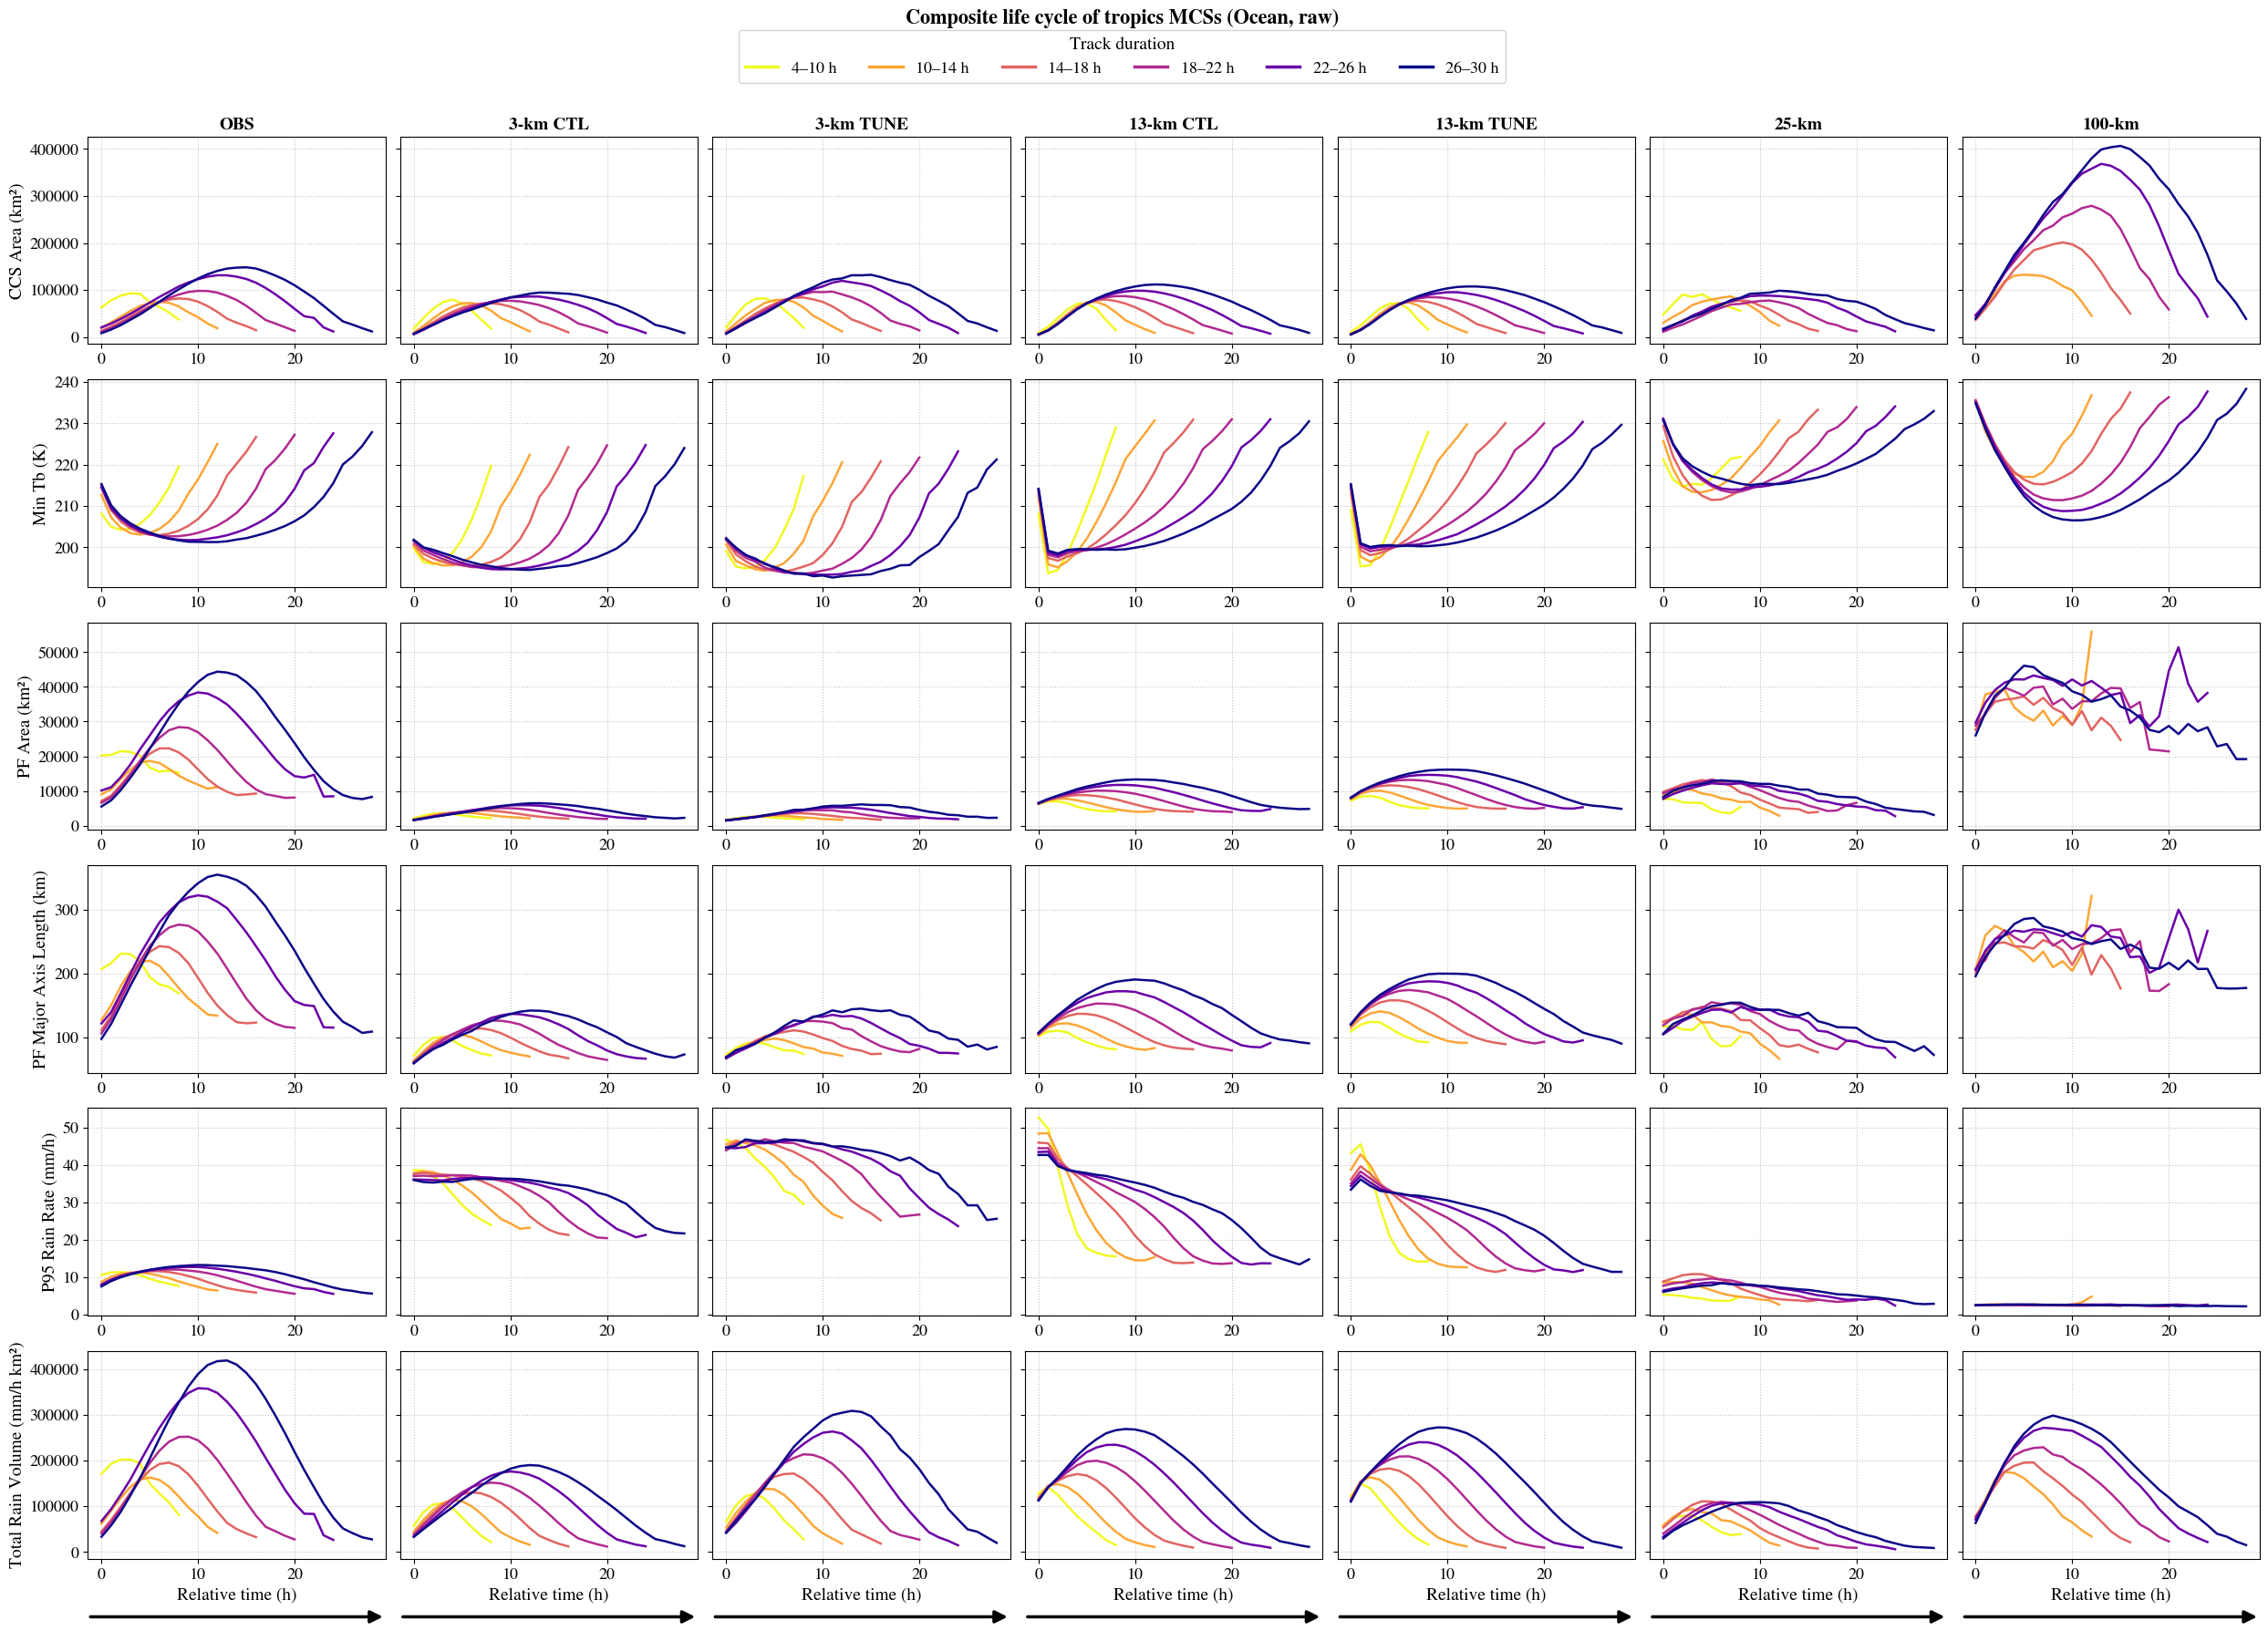

In [14]:
def plot_composite_evolution(composites_panel, panel_order, nrow, ncol, titles, ylabels, figsize, cmap_name='plasma_r', fontsize=12,
                             hspace=0.17, wspace=0.05, xlabel='Relative time (h)', suptitle=None, suptitle_y=0.995, legend_ncols=6,
                             legend_title='Track duration', arrow_y=-0.28, stat='mean'):
    """
    Composite time evolution as M x N panels of lines, one line per duration bin (colors of a colormap), one legend for the figure.

    Args:
        composites_panel: dict
            composites_panel[panel key][bin label] = result dict of composite_track_evolution.
        panel_order: list of str
            Panel keys, row by row (nrow * ncol).
        nrow, ncol: int
            Grid shape.
        titles: list of str
            Titles of the top-row panels (one per column).
        ylabels: list of str
            Y label of every row (leftmost panel).
        figsize: tuple
            Figure size [inch].
        cmap_name: str (default: 'plasma_r')
            Colormap of the bins.
        fontsize, hspace, wspace, xlabel, suptitle, suptitle_y, legend_ncols, legend_title, arrow_y, stat:
            Cosmetics; stat is the central line ('mean' or 'median').

    Returns:
        fig: Figure
    """
    bin_labels = [f'{lo}–{hi} h' for lo, hi in dur_bins]
    cmap = plt.get_cmap(cmap_name, len(bin_labels))
    fig = plt.figure(figsize=figsize)
    # About 1.5 inch above the panels for the title, the legend and the column titles, 0.9 inch below for the x label and the arrow
    gs = fig.add_gridspec(nrow, ncol, hspace=hspace, wspace=wspace, left=0.05, right=0.995, top=1 - 1.5 / figsize[1], bottom=0.9 / figsize[1])
    # The y axis is shared along a row (the same scale for every source)
    axes = []
    for r in range(nrow):
        axes.append([])
        for c in range(ncol):
            axes[r].append(fig.add_subplot(gs[r, c], sharey=(axes[r][0] if c > 0 else None)))
    # Loop over the panels: one line per duration bin
    for idx, key in enumerate(panel_order):
        r, c = divmod(idx, ncol)
        ax = axes[r][c]
        drawn = False
        for i, label in enumerate(bin_labels):
            result = composites_panel[key].get(label)
            if result is not None:
                ax.plot(result['time'], result[stat], color=cmap(i), lw=1.8)
                drawn = True
        if not drawn:
            ax.text(0.5, 0.5, f'no composite\n(fewer than {MIN_TRACKS_COMPOSITE}\ntracks per bin)', ha='center', va='center',
                    transform=ax.transAxes, color='gray', fontsize=fontsize - 2)
            ax.set_xticks([])
        if r == 0:
            ax.set_title(titles[c], fontsize=fontsize, weight='bold', pad=6)
        ax.grid(ls=':', alpha=0.75)
        ax.tick_params(labelsize=fontsize - 1)
        if c == 0:
            ax.set_ylabel(ylabels[r], fontsize=fontsize)
        else:
            ax.tick_params(labelleft=False)
        if r == nrow - 1:
            ax.set_xlabel(xlabel, fontsize=fontsize)
        for spine in ax.spines.values():
            spine.set_color('black')
    # One legend for the figure above the first row, and the arrow of time under the last row
    from matplotlib.lines import Line2D
    fig.legend([Line2D([0], [0], color=cmap(i), lw=2.5) for i in range(len(bin_labels))], bin_labels, title=legend_title, ncol=legend_ncols,
               loc='lower center', bbox_to_anchor=(0.5, 1 - 1.0 / figsize[1]), fontsize=fontsize - 1, title_fontsize=fontsize, framealpha=0.85)
    for ax in axes[-1]:
        ax.annotate('', xy=(1.0, arrow_y), xytext=(0.0, arrow_y), xycoords='axes fraction', annotation_clip=False,
                    arrowprops=dict(arrowstyle='-|>', color='k', lw=2.5, mutation_scale=20))
    if suptitle:
        fig.suptitle(suptitle, fontsize=fontsize + 2, weight='bold', y=1 - 0.1 / figsize[1])
    return fig


for mode in COMPOSITE_MODES:
    for surf in surface_tables:
        panel_order, panel_data = [], {}
        for var in comp_var_specs:
            for label in SOURCE_ORDER:
                key = f'{var}|{label}'
                panel_order.append(key)
                panel_data[key] = composites[mode][surf][var][label]
        fig = plot_composite_evolution(panel_data, panel_order, nrow=len(comp_var_specs), ncol=len(SOURCE_ORDER), titles=SOURCE_ORDER,
                                       ylabels=[spec['ylabel'] for spec in comp_var_specs.values()],
                                       figsize=(3.6 * len(SOURCE_ORDER), 3.0 * len(comp_var_specs)), fontsize=lifecycle_fontsize,
                                       suptitle=f'Composite life cycle of {REGION} MCSs ({surf}, {mode})')
        save_figure(fig, f'composite_by_lifetime_{surf.lower()}_{mode}_{REGION}')
        plt.show()

### Land versus ocean, all sources overlaid
Rows are the variables, the left column the land and the right column the ocean tracks; every source is one line (its color), and the duration
bins of `overlay_bins` are the line styles. The legends above the columns give the number of tracks of every source and bin. A second set of
figures shows one bin with the interquartile range (25th-75th percentile) of every source shaded.

Saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/composite_land_vs_ocean_interpolated_tropics.png


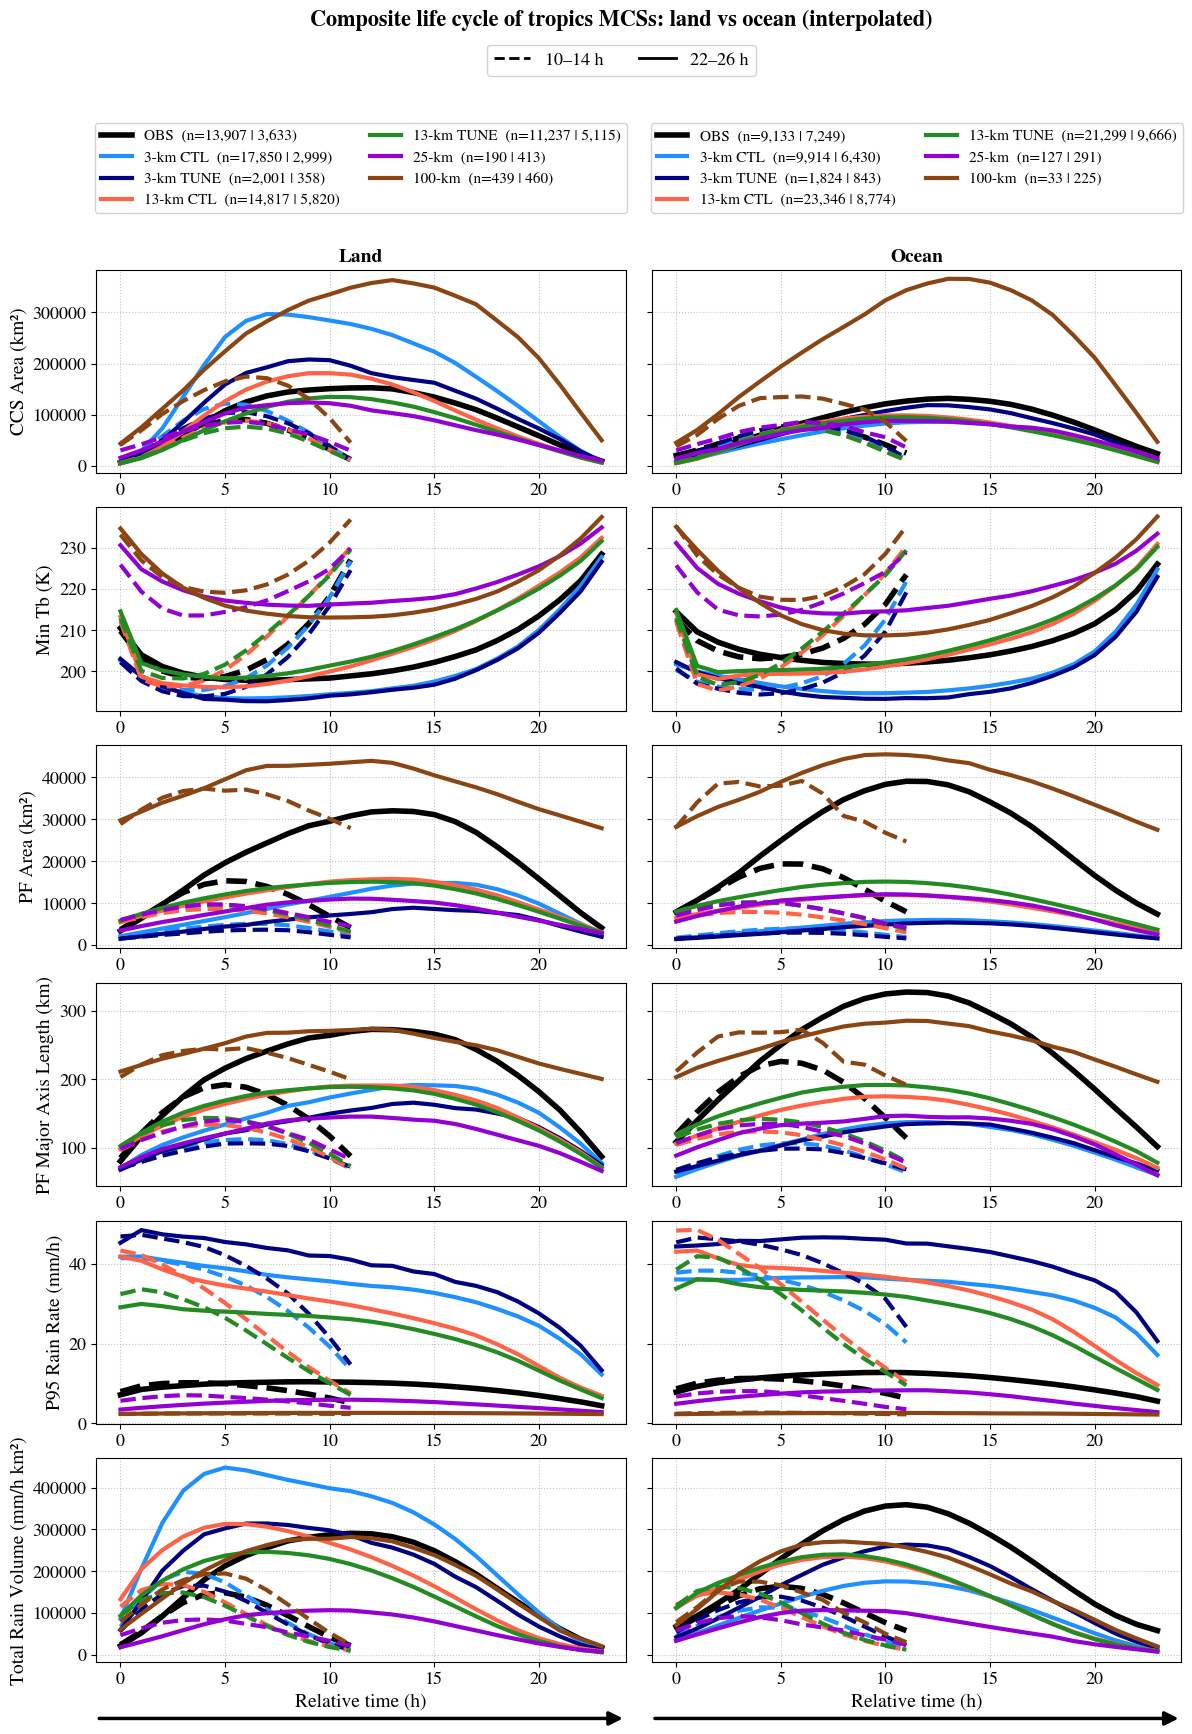

Saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/composite_land_vs_ocean_interpolated_10-14h_iqr_tropics.png


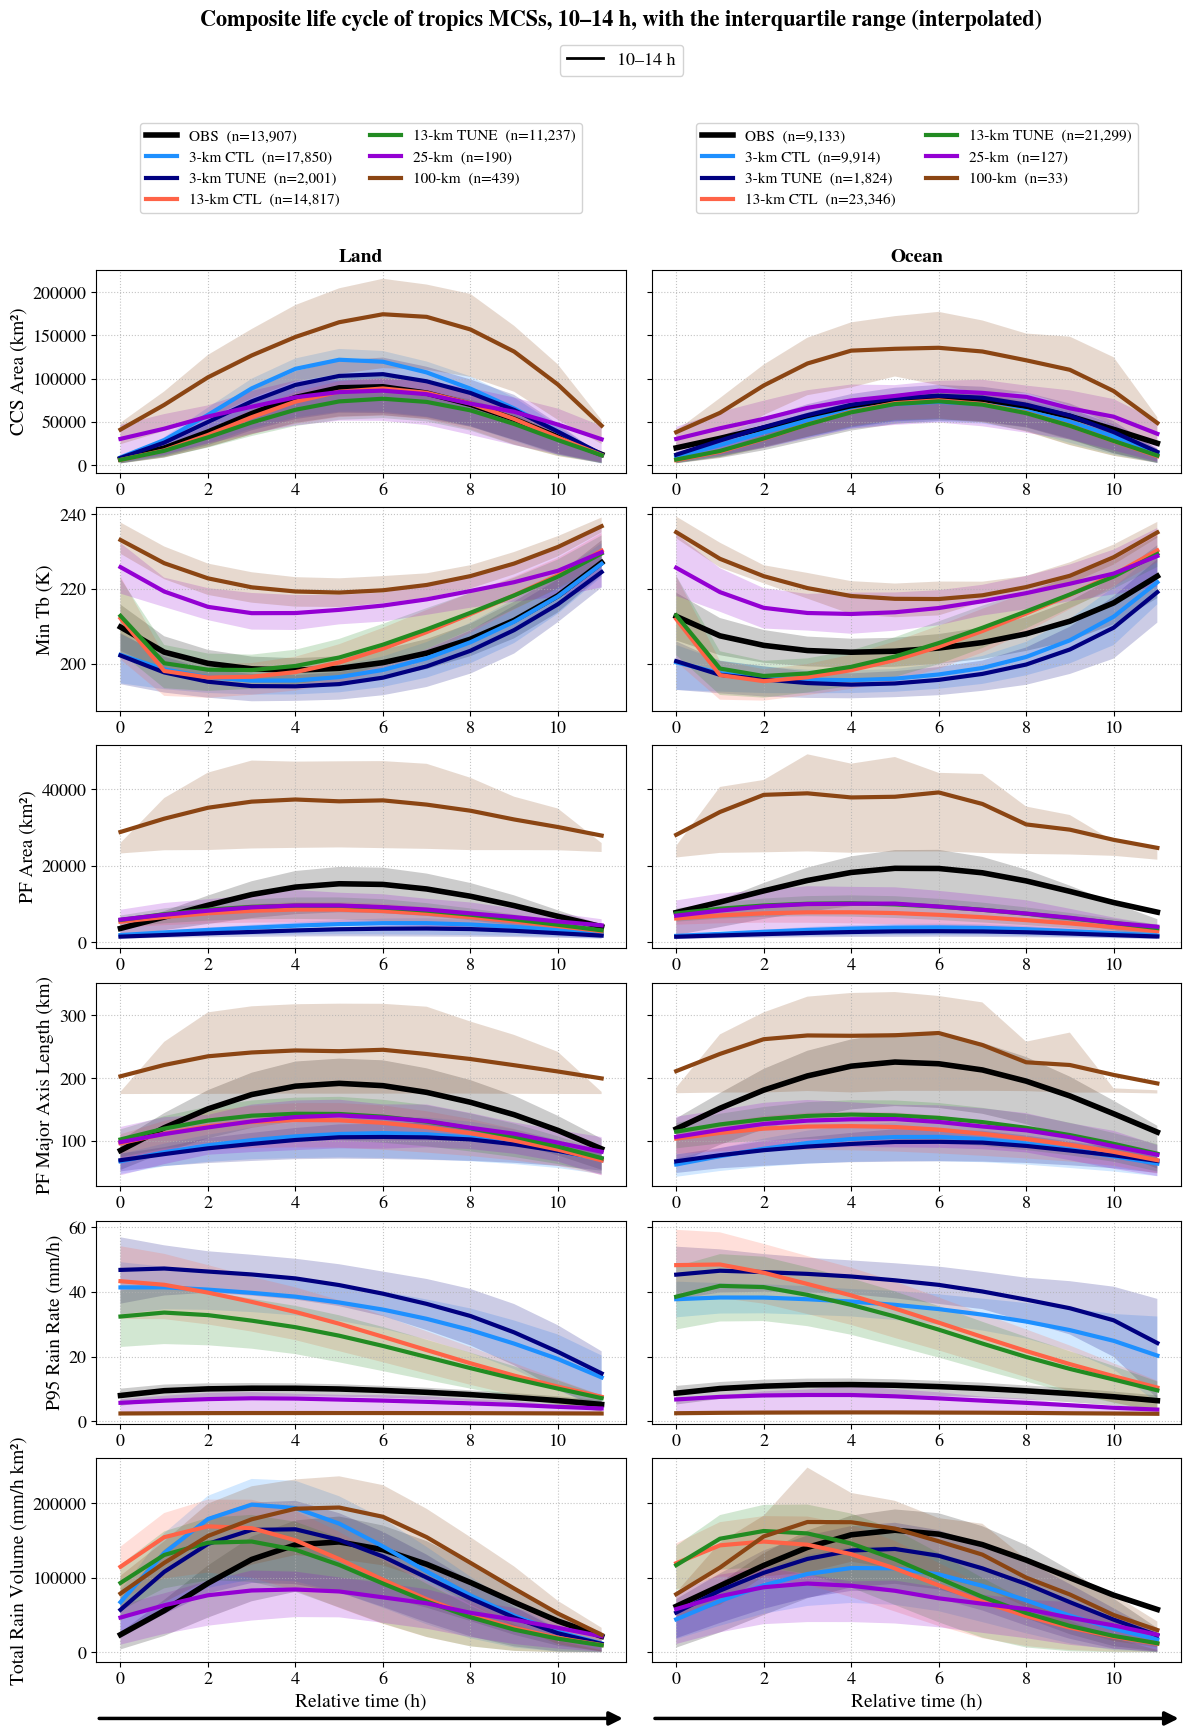

Saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/composite_land_vs_ocean_raw_tropics.png


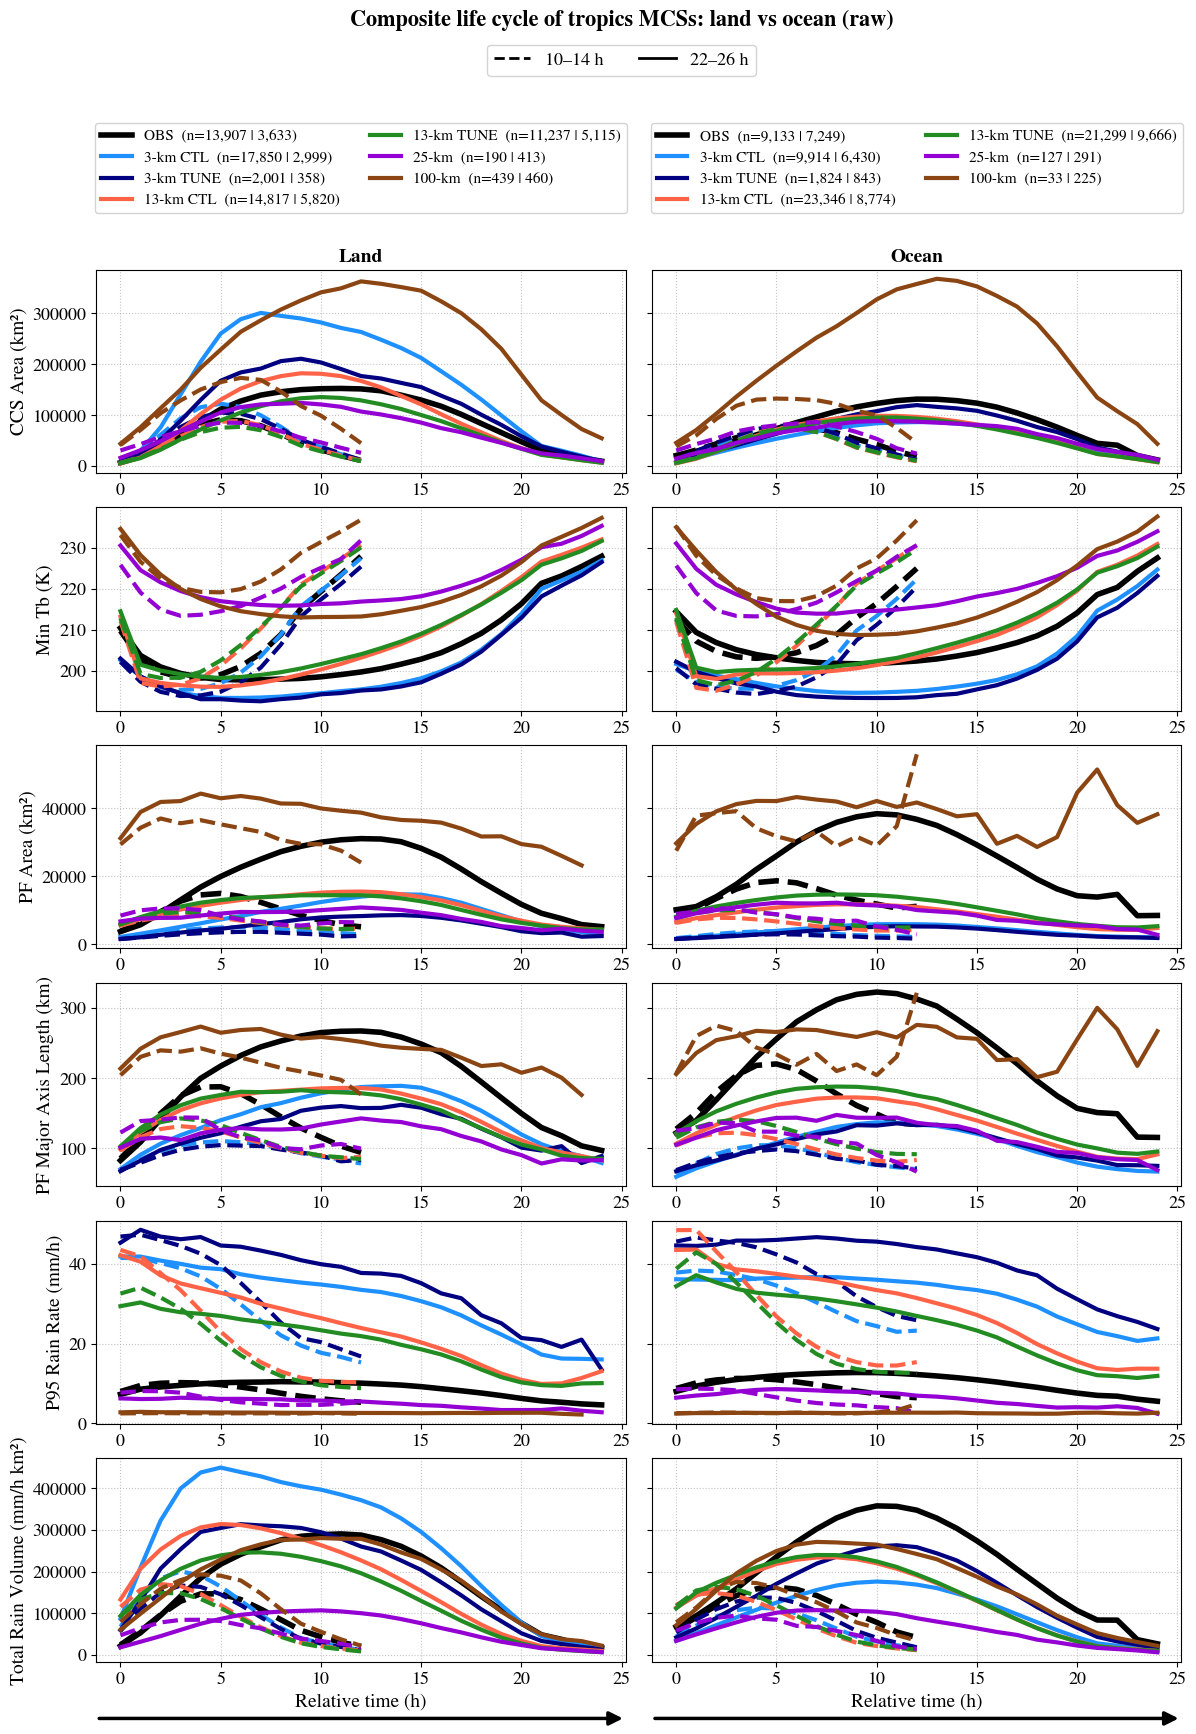

Saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/composite_land_vs_ocean_raw_10-14h_iqr_tropics.png


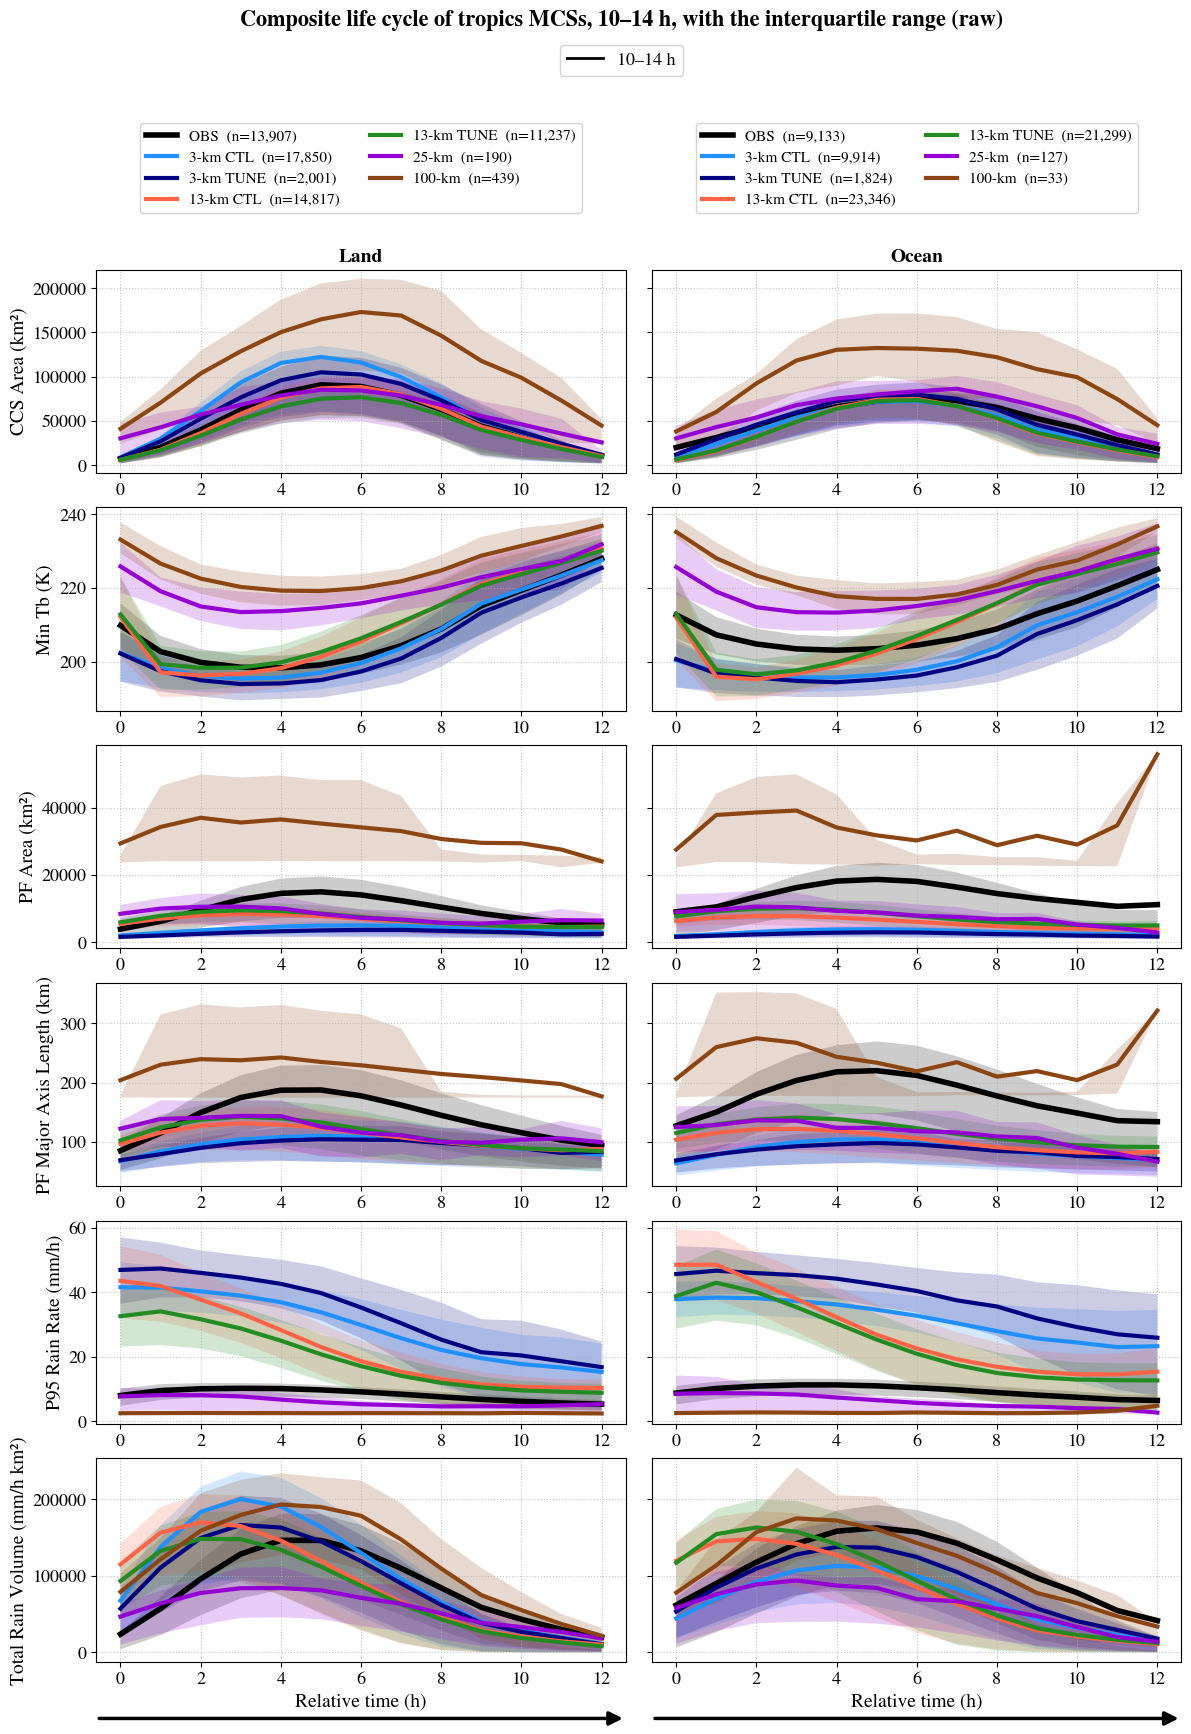

In [15]:
def plot_composite_evolution_shading(composites_panel, panel_order, source_styles, nrow, ncol, titles, ylabels, figsize, bin_styles,
                                     shading=None, stat='mean', fontsize=14, hspace=0.17, wspace=0.05, xlabel='Relative time (h)',
                                     suptitle=None, legend_ncols=2, arrow_y=-0.28):
    """
    Composite time evolution with all sources overlaid in every panel: color = source, line style = duration bin, optional shaded IQR.

    Args:
        composites_panel: dict
            composites_panel[panel key][source label][bin label] = result dict of composite_track_evolution.
        panel_order: list of str
            Panel keys, row by row (nrow * ncol).
        source_styles: dict
            {source label: dict(color, lw, ls)}.
        nrow, ncol: int
            Grid shape.
        titles: list of str
            Titles of the top-row panels (one per column).
        ylabels: list of str
            Y label of every row.
        figsize: tuple
            Figure size [inch].
        bin_styles: dict
            {bin label: dict(ls)}: the bins that are drawn, in the order of the legend, and their line style.
        shading: dict or None (default: None)
            {source label: dict(facecolor, alpha)}: shade q25-q75 of the sources listed.
        stat: str (default: 'mean')
            Central line, 'mean' or 'median'.
        fontsize, hspace, wspace, xlabel, suptitle, legend_ncols, arrow_y:
            Cosmetics (legend_ncols: columns of the legend of the sources above each column).

    Returns:
        fig: Figure
    """
    from matplotlib.lines import Line2D
    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(nrow, ncol, hspace=hspace, wspace=wspace)
    axes = []
    for r in range(nrow):
        axes.append([])
        for c in range(ncol):
            axes[r].append(fig.add_subplot(gs[r, c], sharey=(axes[r][0] if c > 0 else None)))      # land and ocean share the y axis of a row
    # Loop over the panels: a line per source and bin, and the shaded range
    for idx, key in enumerate(panel_order):
        r, c = divmod(idx, ncol)
        ax = axes[r][c]
        for source, style in source_styles.items():
            for bin_label, bstyle in bin_styles.items():
                result = composites_panel[key].get(source, {}).get(bin_label)
                if result is None:
                    continue
                ax.plot(result['time'], result[stat], color=style['color'], lw=style['lw'], ls=bstyle.get('ls', style.get('ls', '-')))
                if shading and source in shading:
                    ax.fill_between(result['time'], result['q25'], result['q75'], facecolor=shading[source]['facecolor'],
                                    alpha=shading[source].get('alpha', 0.3), lw=0)
        if r == 0:
            ax.set_title(titles[c], fontsize=fontsize, weight='bold', pad=6)
        ax.grid(ls=':', alpha=0.75)
        ax.tick_params(labelsize=fontsize - 1)
        if c == 0:
            ax.set_ylabel(ylabels[r], fontsize=fontsize)
        else:
            ax.tick_params(labelleft=False)
        if r == nrow - 1:
            ax.set_xlabel(xlabel, fontsize=fontsize)
        for spine in ax.spines.values():
            spine.set_color('black')
    # Legends above the panels: the sources of every column (with the tracks per bin), and above them the bins (line styles)
    n_rows_legend = int(np.ceil(len(source_styles) / legend_ncols))
    reserved_in = 0.9 + 0.3 * n_rows_legend
    fig.subplots_adjust(top=max(0.5, 1 - reserved_in / figsize[1]))
    top = axes[0][0].get_position().y1 + (fontsize + 8) / (figsize[1] * 72)      # above the column titles
    for c in range(ncol):
        pos = axes[0][c].get_position()
        handles, labels = [], []
        for source, style in source_styles.items():
            counts = []
            for bin_label in bin_styles:
                res = composites_panel[panel_order[c]].get(source, {}).get(bin_label)
                counts.append(f'{res["n_tracks"]:,}' if res else '0')
            handles.append(Line2D([0], [0], color=style['color'], lw=style['lw']))
            labels.append(f'{source}  (n={" | ".join(counts)})')
        fig.legend(handles, labels, loc='lower center', bbox_to_anchor=((pos.x0 + pos.x1) / 2, top + 0.01), ncol=legend_ncols,
                   frameon=True, framealpha=0.85, fontsize=fontsize - 3)
    row_h = (fontsize + 3) / (figsize[1] * 72)
    fig.legend([Line2D([0], [0], color='k', lw=2, ls=bs.get('ls', '-')) for bs in bin_styles.values()], list(bin_styles), loc='lower center',
               bbox_to_anchor=(0.5, top + 0.01 + row_h * n_rows_legend * 1.25 + 0.01), ncol=len(bin_styles), frameon=True, framealpha=0.85,
               fontsize=fontsize - 1)
    for ax in axes[-1]:
        ax.annotate('', xy=(1.0, arrow_y), xytext=(0.0, arrow_y), xycoords='axes fraction', annotation_clip=False,
                    arrowprops=dict(arrowstyle='-|>', color='k', lw=2.5, mutation_scale=20))
    if suptitle:
        fig.suptitle(suptitle, fontsize=fontsize + 2, weight='bold', y=1.0 + 0.5 / figsize[1])
    return fig


overlay_source_styles = {cfg['label']: dict(color=cfg['color'], lw=(OVERLAY_LW_OBS if key == REF_SOURCE else OVERLAY_LW), ls='-')
                         for key, cfg in SOURCES.items()}
overlay_shading = {cfg['label']: dict(facecolor=cfg['color'], alpha=OVERLAY_SHADING_ALPHA) for cfg in SOURCES.values()}
for mode in COMPOSITE_MODES:
    # Panels: rows = variables, columns = land / ocean
    panel_order, panel_data = [], {}
    for var in comp_var_specs:
        for surf in SURFACE_ORDER:
            key = f'{var}|{surf}'
            panel_order.append(key)
            panel_data[key] = {label: composites[mode][surf][var][label] for label in SOURCE_ORDER}
    common = dict(panel_order=panel_order, source_styles=overlay_source_styles, nrow=len(comp_var_specs), ncol=len(SURFACE_ORDER),
                  titles=SURFACE_ORDER, ylabels=[spec['ylabel'] for spec in comp_var_specs.values()],
                  figsize=(7 * len(SURFACE_ORDER), 3 * len(comp_var_specs)), fontsize=lifecycle_fontsize)
    # (1) The two duration bins of overlay_bins, no shading
    fig = plot_composite_evolution_shading(panel_data, bin_styles=overlay_bins, shading=None,
                                           suptitle=f'Composite life cycle of {REGION} MCSs: land vs ocean ({mode})', **common)
    save_figure(fig, f'composite_land_vs_ocean_{mode}_{REGION}')
    plt.show()
    # (2) One bin with the shaded interquartile range
    fig = plot_composite_evolution_shading(panel_data, bin_styles={overlay_shading_bin: dict(ls='-')}, shading=overlay_shading,
                                           suptitle=f'Composite life cycle of {REGION} MCSs, {overlay_shading_bin}, with the interquartile range ({mode})',
                                           **common)
    save_figure(fig, f'composite_land_vs_ocean_{mode}_{overlay_shading_bin.replace(" ", "").replace("–", "-")}_iqr_{REGION}')
    plt.show()